# Integración de generación térmica

**Guía de lectura:** §§1–10: referencia histórica 0A; §§12–15: referencia
histórica 0B; §§16–18: escenario documental de fabricante; §§19–22: Caso 0C temporal; §§23–25: energía durante eventos; §§26–28: cargo por arranque; §29: contraste con PyPSA. Los supuestos y
conclusiones de cada bloque aplican exclusivamente a ese bloque.

## 1 · Caso 0A histórico, gas a 16 USD/MMBtu

Primera etapa de la línea de integración térmica. Construye y valida el sistema
energético del usuario industrial **antes** de incorporar generación solar y
almacenamiento:

```
RED  +  GENERACIÓN TÉRMICA  ──►  DEMANDA
```

**Qué NO incluye todavía**, deliberadamente: PV, BESS, rolling horizon, previsión
perfecta anual, metaheurísticas, unit commitment completo, rampas, costos de
arranque, tiempos mínimos de encendido y apagado, y **mínimos técnicos**. El
despacho de esta versión es un **orden de mérito sin variables binarias**.

El propósito es validar el despacho térmico frente a la red con un modelo lo
bastante simple como para auditarlo línea a línea.

## Cómo está organizado

| capa | archivo | papel |
|---|---|---|
| Modelo | `termica.py` | parámetros de las unidades, despachos 0A/0B/0C, eventos, cargo por arranque y validadores |
| Pruebas | `termica_pruebas.py` | casos sintéticos y contraste de la programación dinámica contra un MILP independiente, también en una ventana real de 72 h |
| Cálculo | `termica_barridos.py` | carga demanda y señales del cuaderno 02, corre las pruebas y los barridos, valida y escribe `resultados_nb11/` |
| Contraste | `termica_pypsa.py`, `termica_pypsa_pruebas.py`, `termica_pypsa_eventos.py` | el mismo problema formulado en PyPSA, resuelto con HiGHS y comparado con la programación dinámica; escribe `resultados_nb11/pypsa_*` |
| Lectura | este cuaderno | solo lee esos CSV, muestra tablas y figuras y redacta la lectura de resultados |

La demanda horaria y las señales T0 y T1 vienen del cuaderno 02, fuente de verdad
del proyecto, a través de `benchmark_optimo.cargar_entorno_nb02()`; la TRM, de
`costos.py`. **Este cuaderno no resuelve ningún despacho:** una guarda al inicio
interrumpe la ejecución si alguna celda intentara llamar a los solvers de
`termica.py`. Para recalcular hay que correr primero

```
.venv/Scripts/python.exe termica_barridos.py
```

que tarda unos 15 minutos. Todas las figuras se regeneran desde los CSV vigentes;
las seis primeras usan `.build/figuras_nb11_corregidas.py`.

In [1]:
import sys, warnings, inspect
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown

warnings.filterwarnings("ignore")

import costos
import termica as T

FIG = Path("figuras_nb11"); FIG.mkdir(exist_ok=True)
SAL = Path("resultados_nb11")

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

# Documentación de los algoritmos, tomada antes de activar la guarda.
DOC = {n: inspect.getdoc(getattr(T, n)) for n in (
    "enumerar_termico", "resolver_compromiso_temporal", "rearranques_tras_demanda_baja",
    "contraste_milp_compromiso", "resolver_eventos")}

# --- Guarda: este cuaderno solo lee CSV. Si algo intenta recalcular, para. ---
def _prohibido(nombre):
    def _f(*a, **k):
        raise RuntimeError(
            "El cuaderno 11 no debe recalcular nada: se intentó llamar a {}. Las fuentes "
            "son los CSV de resultados_nb11/, que escribe termica_barridos.py.".format(nombre))
    return _f

for _nombre in ("cargar_entradas", "despachar_merito", "enumerar_termico",
                "resolver_compromiso_temporal", "resolver_eventos", "contraste_milp_compromiso"):
    setattr(T, _nombre, _prohibido(_nombre))

# Paleta validada con .build/validar_paleta.py sobre #fcfcfb:
# vision normal PASS, tritan PASS, contraste PASS; deutan y protan quedan en
# WARN para el par G3<->Red, por eso las series llevan etiqueta directa.
COLOR = {"G1": "#2a78d6", "G2": "#eb6834", "G3": "#a03060",
         "G4": "#0d5f4f", "Red": "#8b8a83"}
C_T0, C_T1 = "#7048c0", "#c07a00"
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#d8d8d4", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#d8d8d4", "font.size": 9.5})

VERIF = pd.read_csv(SAL / "termica_verificaciones.csv")
assert (VERIF.Estado == "OK").all(), "hay controles fallidos en termica_barridos.py"
print("TRM {:,.2f} COP/USD, vigente al {}".format(costos.TRM_COP_USD, costos.TRM_FECHA_REFERENCIA))
print("{} controles de termica_barridos.py en estado OK; última corrida en {:.1f} min.".format(
    len(VERIF), float(VERIF.loc[VERIF.Bloque == "total", "Valor"].iloc[0])))

TRM 3,126.08 COP/USD, vigente al 2026-09-05
17 controles de termica_barridos.py en estado OK; última corrida en 13.3 min.


## 2 · Demanda y señales económicas

Se cargan del cuaderno 02, que es la fuente de verdad del proyecto para la serie
de demanda depurada y para la construcción de las dos señales de precio.

In [2]:
D0 = {s: pd.read_csv(SAL / "caso0_despacho_{}.csv".format(s), parse_dates=["Fecha"]) for s in T.SENALES}
LOAD = D0["T0"].Demanda_MW.to_numpy()
FECHA = pd.DatetimeIndex(D0["T0"].Fecha)
DT, N = T.DT, len(LOAD)
TRM = costos.TRM_COP_USD
SENALES = T.SENALES
NOMBRE = {"T0": "T0 — señal cuasi-plana", "T1": "T1 — señal horaria indexada"}
# Las señales en USD/MWh se guardan con cada despacho; son las mismas en todos los CSV.
C_IMP_USD = {s: pd.read_csv(SAL / "fabricante_0B_gas16_{}.csv".format(s)).Precio_red_USD_MWh.to_numpy()
             for s in SENALES}

print("Demanda del usuario industrial")
print("  horas            {:>12,}".format(N))
print("  energia anual    {:>12,.1f} MWh".format(LOAD.sum() * DT))
print("  potencia media   {:>12.2f} MW".format(LOAD.mean()))
print("  potencia maxima  {:>12.2f} MW".format(LOAD.max()))
print("  potencia minima  {:>12.2f} MW".format(LOAD.min()))
print("  factor de carga  {:>12.1%}".format(LOAD.mean() / LOAD.max()))
print()
print("Senales de precio de importacion")
for s in SENALES:
    v = C_IMP_USD[s] * TRM
    print("  {}  {:<30} COP/MWh  min {:>9,.0f}  media {:>9,.0f}  max {:>10,.0f}".format(
        s, NOMBRE[s].split("—")[-1].strip(), v.min(), v.mean(), v.max()))

assert N == 8760, "se esperaban 8.760 pasos horarios"
assert abs(LOAD.sum() * DT - 158742.6) < 1.0, "la demanda anual no es la esperada"
assert abs(LOAD.mean() - 18.12) < 0.01 and abs(LOAD.max() - 23.23) < 0.01
print("\nLa serie coincide con la del proyecto: 158.742,6 MWh, media 18,12 MW, pico 23,23 MW.")

Demanda del usuario industrial
  horas                   8,760
  energia anual       158,742.6 MWh
  potencia media          18.12 MW
  potencia maxima         23.23 MW
  potencia minima          0.13 MW
  factor de carga         78.0%

Senales de precio de importacion
  T0  señal cuasi-plana              COP/MWh  min   653,225  media   657,428  max    659,950
  T1  señal horaria indexada         COP/MWh  min   510,247  media   653,199  max  2,636,397

La serie coincide con la del proyecto: 158.742,6 MWh, media 18,12 MW, pico 23,23 MW.


## 3 · Los cuatro generadores a gas

Parámetros declarados por el usuario. La potencia **disponible** es la que limita
el despacho; la nominal se conserva como referencia.

El mínimo técnico se declara aquí pero **no se aplica al Caso 0A**: entra en
la sección de Caso 0B, mediante enumeración exacta de estados.

In [3]:
GEN = T.unidades_historicas()
display(GEN)
print("potencia nominal total    {:>6.1f} MW".format(GEN.P_nom_MW.sum()))
print("potencia disponible total {:>6.1f} MW".format(GEN.P_disp_MW.sum()))
P_DISP_TOTAL = float(GEN.P_disp_MW.sum())
PMIN, PMAX = GEN.P_min_MW.to_numpy(), GEN.P_disp_MW.to_numpy()
HR, CVOM = GEN.HeatRate_MMBtu_MWh.to_numpy(), GEN.CV_adicional_USD_MWh.to_numpy()
assert abs(GEN.P_nom_MW.sum() - 31.0) < 1e-9
assert abs(P_DISP_TOTAL - 25.2) < 1e-9
print()
print("La capacidad termica disponible ({:.1f} MW) supera el pico de demanda "
      "({:.2f} MW).".format(P_DISP_TOTAL, LOAD.max()))
print("La red no es estructuralmente necesaria: entra solo por economia.")

,P_nom_MW,P_disp_MW,HeatRate_MMBtu_MWh,CV_adicional_USD_MWh,P_min_MW
Unidad,,,,,
G1,10.0,8.0,8.0000,9.28,2.40
G2,10.0,8.0,8.0000,9.28,2.40
G3,7.0,6.0,10.0000,9.28,1.80
G4,4.0,3.2,8.0576,9.28,0.96


potencia nominal total      31.0 MW
potencia disponible total   25.2 MW

La capacidad termica disponible (25.2 MW) supera el pico de demanda (23.23 MW).
La red no es estructuralmente necesaria: entra solo por economia.


## 4 · Precio del gas

La historia económica relevante del usuario tiene tres puntos. **El Caso 0A
(§§1–10) usa solo el precio actual, 16 USD/MMBtu.** Los escenarios de 8 y
20 USD/MMBtu se ejecutan a partir del Caso 0B (§12) y en todos los bloques
posteriores.

In [4]:
ESCENARIOS_GAS = T.ESCENARIOS_GAS
GAS_USD_MMBTU = ESCENARIOS_GAS["actual"]
for k, v in ESCENARIOS_GAS.items():
    marca = "   <- caso 0A" if v == GAS_USD_MMBTU else ""
    print("  {:<14}{:>6.1f} USD/MMBtu{}".format(k, v, marca))

  historico        8.0 USD/MMBtu
  actual          16.0 USD/MMBtu   <- caso 0A
  futuro_2033     20.0 USD/MMBtu


## 5 · Costo marginal de cada generador

$$CV_g = HeatRate_g \times PrecioGas + CV^{adicional}_g \qquad [\mathrm{USD/MWh}]$$

El término adicional de 9,28 USD/MWh es el mismo para las cuatro unidades y
agrupa los costos variables no asociados al combustible.

In [5]:
GEN["CV_USD_MWh"] = T.costo_marginal(GEN, GAS_USD_MMBTU)
GEN["Costo_combustible_USD_MWh"] = GEN.HeatRate_MMBtu_MWh * GAS_USD_MMBTU
display(GEN[["HeatRate_MMBtu_MWh", "Costo_combustible_USD_MWh",
             "CV_adicional_USD_MWh", "CV_USD_MWh"]].round(4))
ESPERADO_CV = {"G1": 137.28, "G2": 137.28, "G3": 169.28, "G4": 138.20}
for u, esperado in ESPERADO_CV.items():
    obtenido = float(GEN.loc[u, "CV_USD_MWh"])
    assert abs(obtenido - esperado) <= 0.01
    print("  {}  CV = {:>10.4f} USD/MWh   esperado {:>7.2f}   OK".format(u, obtenido, esperado))
print()
print("orden de merito termico (mas barato primero): {}".format(
    " < ".join(GEN.CV_USD_MWh.sort_values().index)))
print("G1 y G2 tienen el mismo costo marginal; el desempate es por orden de")
print("declaracion y no tiene efecto economico.")

,HeatRate_MMBtu_MWh,Costo_combustible_USD_MWh,CV_adicional_USD_MWh,CV_USD_MWh
Unidad,,,,
G1,8.0000,128.0000,9.28,137.2800
G2,8.0000,128.0000,9.28,137.2800
G3,10.0000,160.0000,9.28,169.2800
G4,8.0576,128.9216,9.28,138.2016


  G1  CV =   137.2800 USD/MWh   esperado  137.28   OK
  G2  CV =   137.2800 USD/MWh   esperado  137.28   OK
  G3  CV =   169.2800 USD/MWh   esperado  169.28   OK
  G4  CV =   138.2016 USD/MWh   esperado  138.20   OK

orden de merito termico (mas barato primero): G1 < G2 < G4 < G3
G1 y G2 tienen el mismo costo marginal; el desempate es por orden de
declaracion y no tiene efecto economico.


## 6 · Conversión de moneda

Las señales de red del proyecto están en **COP/MWh** y los costos térmicos en
**USD/MWh**. La comparación se hace en USD/MWh usando la **misma TRM congelada
del proyecto**, sin introducir ningún supuesto nuevo.

In [6]:
print("TRM = {:,.2f} COP/USD  (fecha de referencia {})".format(TRM, costos.TRM_FECHA_REFERENCIA))
print()
print("Costo de importacion de red en USD/MWh")
print("  {:<6}{:>10}{:>10}{:>10}{:>10}".format("senal", "min", "media", "max", "p95"))
for s in SENALES:
    v = C_IMP_USD[s]
    print("  {:<6}{:>10.2f}{:>10.2f}{:>10.2f}{:>10.2f}".format(
        s, v.min(), v.mean(), v.max(), np.percentile(v, 95)))
print()
print("Horas del anio en que la red resulta mas barata que cada unidad termica:")
print("  {:<6}{:>10}{:>10}{:>10}{:>10}".format("senal", "G1/G2", "G4", "G3", "% del anio con G3"))
for s in SENALES:
    v = C_IMP_USD[s]
    n12 = int((v < GEN.loc["G1", "CV_USD_MWh"]).sum())
    n4 = int((v < GEN.loc["G4", "CV_USD_MWh"]).sum())
    n3 = int((v < GEN.loc["G3", "CV_USD_MWh"]).sum())
    print("  {:<6}{:>10,}{:>10,}{:>10,}{:>9.1f} %".format(s, n12, n4, n3, n3 / len(v) * 100))

TRM = 3,126.08 COP/USD  (fecha de referencia 2026-09-05)

Costo de importacion de red en USD/MWh
  senal        min     media       max       p95
  T0        208.96    210.30    211.11    211.11
  T1        163.22    208.95    843.36    357.18

Horas del anio en que la red resulta mas barata que cada unidad termica:
  senal      G1/G2        G4        G3% del anio con G3
  T0             0         0         0      0.0 %
  T1             0         0     3,389     38.7 %


Esta tabla explica de antemano por qué las dos señales producen despachos
distintos en el Caso 0A. Vale **solo para gas a 16 USD/MMBtu y los HR
históricos**: a gas 20, o con los HR de fabricante del §16, los cruces cambian.

- bajo **T0** la red es más cara que las cuatro unidades en **todas** las horas,
  así que el orden de mérito es puramente térmico y la red solo cubriría un
  déficit de capacidad que aquí no existe;
- bajo **T1** la red sigue siendo más cara que G1, G2 y G4 en todas las horas,
  pero es **más barata que G3 en una fracción apreciable del año**. Ahí aparece
  la única competencia real entre red y generación propia.

## 7 · Despacho horario por orden de mérito

**Sin variables binarias y sin mínimos técnicos.** Para cada hora se ordenan las
cinco fuentes —las cuatro unidades y la red— por costo creciente y se atiende la
demanda desde la más barata, respetando la potencia disponible de cada unidad.

$$Load_t = P^{G1}_t + P^{G2}_t + P^{G3}_t + P^{G4}_t + P^{red}_t$$

$$0 \le P^{g}_t \le P^{disp}_g \qquad P^{red}_t \ge 0 \qquad \text{sin exportación}$$

Los generadores se mantienen **individualmente** y no se agregan en una sola
planta de 25,2 MW, porque G3 tiene un costo marginal distinto del resto.

La implementación es vectorizada y genérica: no codifica un orden de mérito fijo,
lo deriva de los costos hora a hora. Así sigue siendo correcta si cambia el
precio del gas o la señal de red.

In [7]:
FUENTES = T.FUENTES
DESPACHO = {s: D0[s][FUENTES] for s in SENALES}
print("Primeras horas bajo T1 [MW]:")
display(DESPACHO["T1"].head(6).round(4).assign(Demanda=LOAD[:6].round(4)))

Primeras horas bajo T1 [MW]:


,G1,G2,G3,G4,Red,Demanda
0,8.0,8.0,1.56,3.2,0.0,20.76
1,8.0,8.0,1.74,3.2,0.0,20.94
2,8.0,8.0,1.53,3.2,0.0,20.73
3,8.0,8.0,1.75,3.2,0.0,20.95
4,8.0,8.0,1.84,3.2,0.0,21.04
5,8.0,8.0,1.84,3.2,0.0,21.04


## 8 · Validaciones automáticas

Si alguna falla es un error real del modelo. **No relajar la tolerancia para que
pase.**

In [8]:
display(VERIF[VERIF.Bloque == "0A"])
for s in SENALES:
    d = DESPACHO[s]
    print("{}  balance horario: residuo maximo {:.2e} MW".format(
        s, np.abs(d.sum(axis=1).to_numpy() - LOAD).max()))
    print("{}  termico maximo {:.4f} MW de {:.1f} disponibles".format(
        s, d[list(GEN.index)].sum(axis=1).max(), P_DISP_TOTAL))
print("\nLas ocho validaciones pasan en las dos senales.")

,Bloque,Control,Valor,Estado
5,0A,Demanda anual [MWh],1.587426e+05,OK
6,0A,T0 ocho validaciones de mérito; residuo de bal...,0.000000e+00,OK
7,0A,T1 ocho validaciones de mérito; residuo de bal...,3.552714e-15,OK
8,0A,Regresión independiente: 4 CSV de 0A iguales a...,0.000000e+00,OK


T0  balance horario: residuo maximo 3.55e-15 MW
T0  termico maximo 23.2300 MW de 25.2 disponibles
T1  balance horario: residuo maximo 3.55e-15 MW
T1  termico maximo 23.2300 MW de 25.2 disponibles

Las ocho validaciones pasan en las dos senales.


## 9 · Indicadores anuales

$$Gas_g = E_g \times HeatRate_g \quad [\mathrm{MMBtu}] \qquad
Combustible_g = Gas_g \times PrecioGas \quad [\mathrm{USD}]$$

$$Costo^{red} = \sum_t P^{red}_t \cdot c^{imp}_t \cdot \Delta t$$

In [9]:
KPI_UNIDAD = pd.read_csv(SAL / "caso0_kpis_por_unidad.csv", index_col=[0, 1])
COMP = pd.read_csv(SAL / "caso0_kpis_por_senal.csv", index_col=0)
display(KPI_UNIDAD.round(2))
display(COMP.round(2))

Energia_MWh  Participacion_pct  Horas_operacion  Factor_planta_pct  Gas_MMBtu  Combustible_USD  CV_adicional_USD  Costo_total_USD
Senal Unidad                                                                                                                                   
T0    G1         69373.90              43.70             8760              98.99  554991.20       8879859.20         643789.79       9523648.99
      G2         65864.94              41.49             8645              93.99  526919.48       8430711.68         611226.60       9041938.28
      G3          4929.06               3.11             4384               9.38   49290.65        788650.40          45741.72        834392.12
      G4         18574.66              11.70             6749              66.26  149667.22       2394675.53         172372.89       2567048.42
T1    G1         69373.90              43.70             8760              98.99  554991.20       8879859.20         643789.79       9523648.99
      G2         65864.94              41.49             8645              93.99  526919.48       8430711.68         611226.60       9041938.28
      G3          3433.18               2.16             2986               6.53   34331.75        549308.00          31859.86        581167.86
      G4         18574.66              11.70             6749              66.26  149667.22       2394675.53         172372.89       2567048.42

,T0,T1
Energia_termica_MWh,158742.56,157246.67
Participacion_termica_pct,100.00,99.06
Energia_red_MWh,0.00,1495.89
Participacion_red_pct,0.00,0.94
Gas_total_MMBtu,1280868.55,1265909.65
Costo_combustible_USD,20493896.81,20254554.41
Costo_variable_adicional_USD,1473131.00,1459249.14
Costo_total_termico_USD,21967027.81,21713803.56
Costo_compras_red_USD,0.00,249370.71
Costo_total_abastecimiento_USD,21967027.81,21963174.26


## 10 · Gráficas de diagnóstico

Seis figuras regeneradas desde CSV corregidos


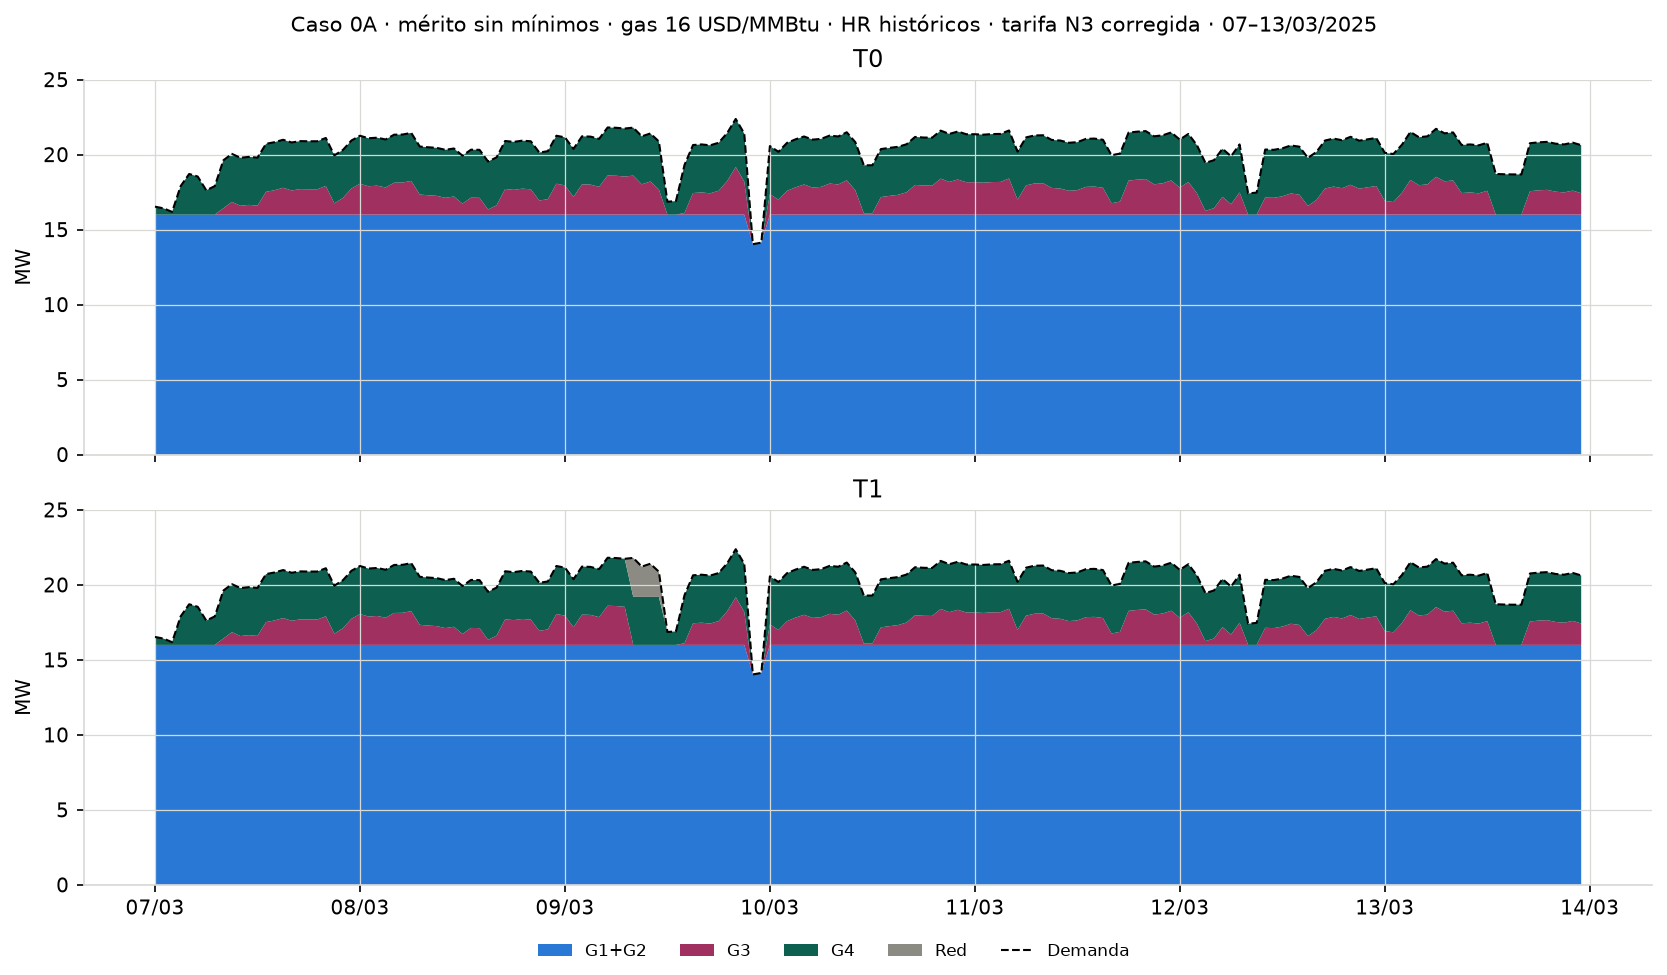

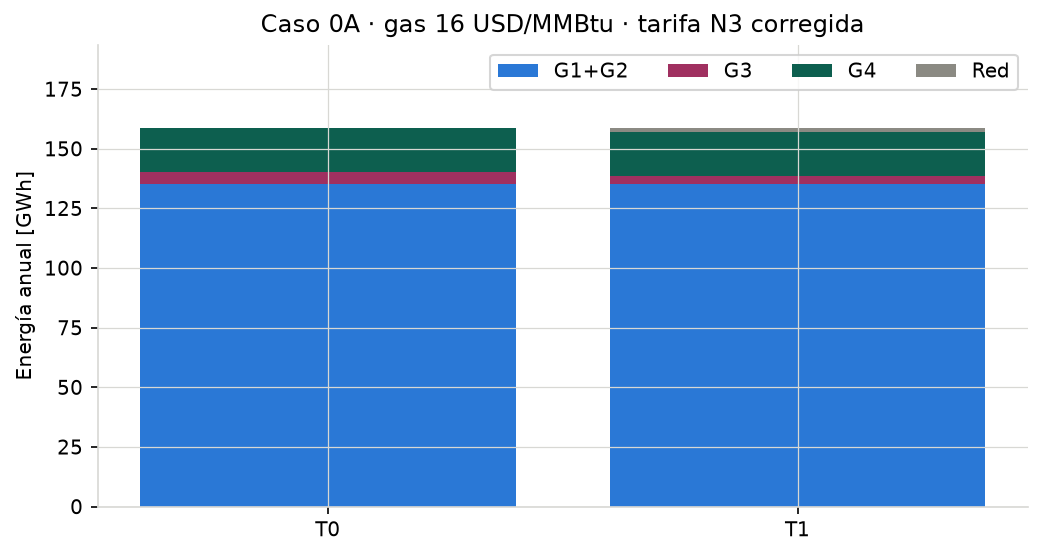

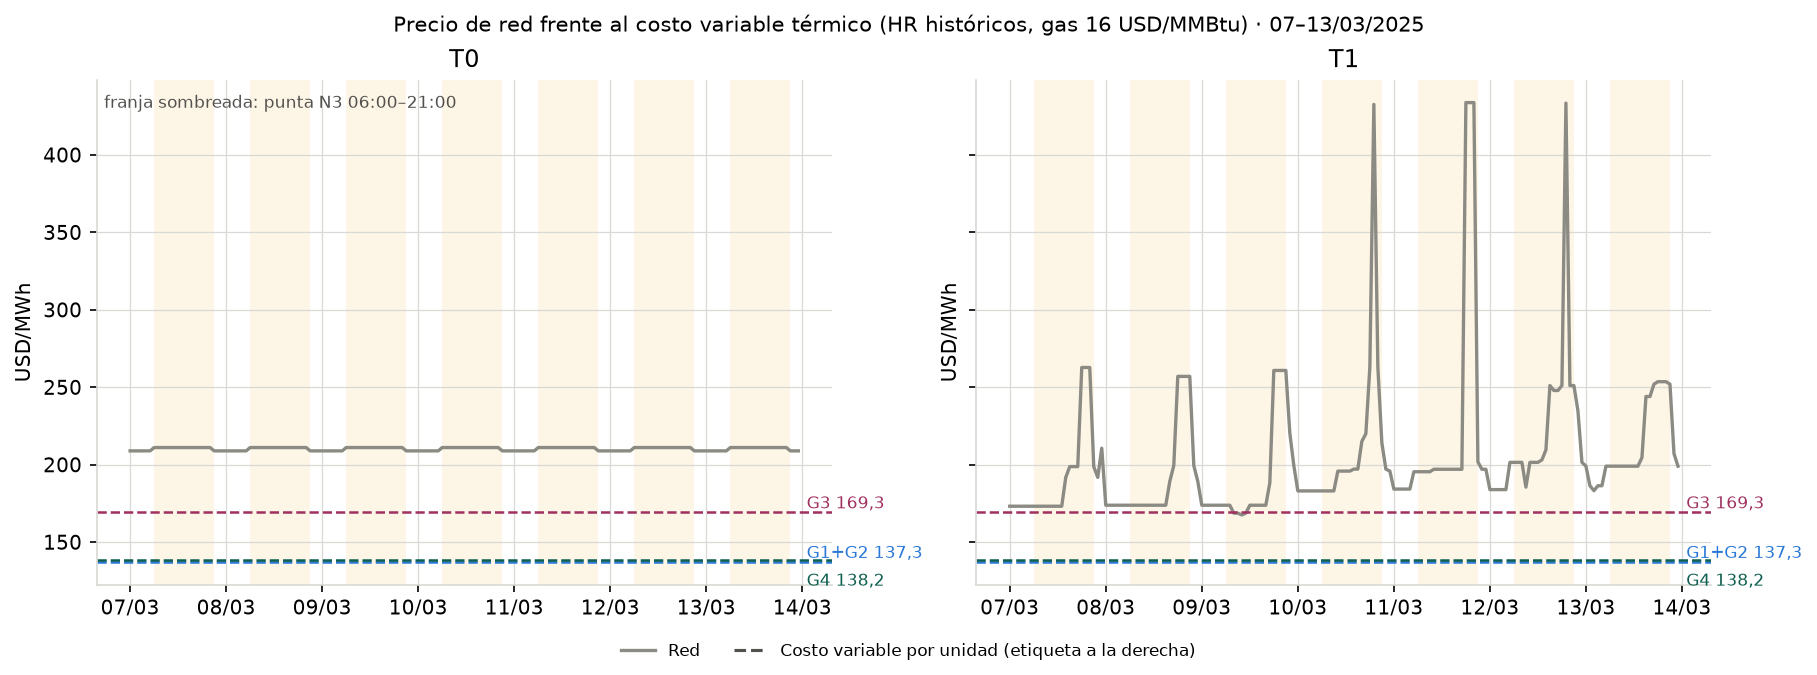

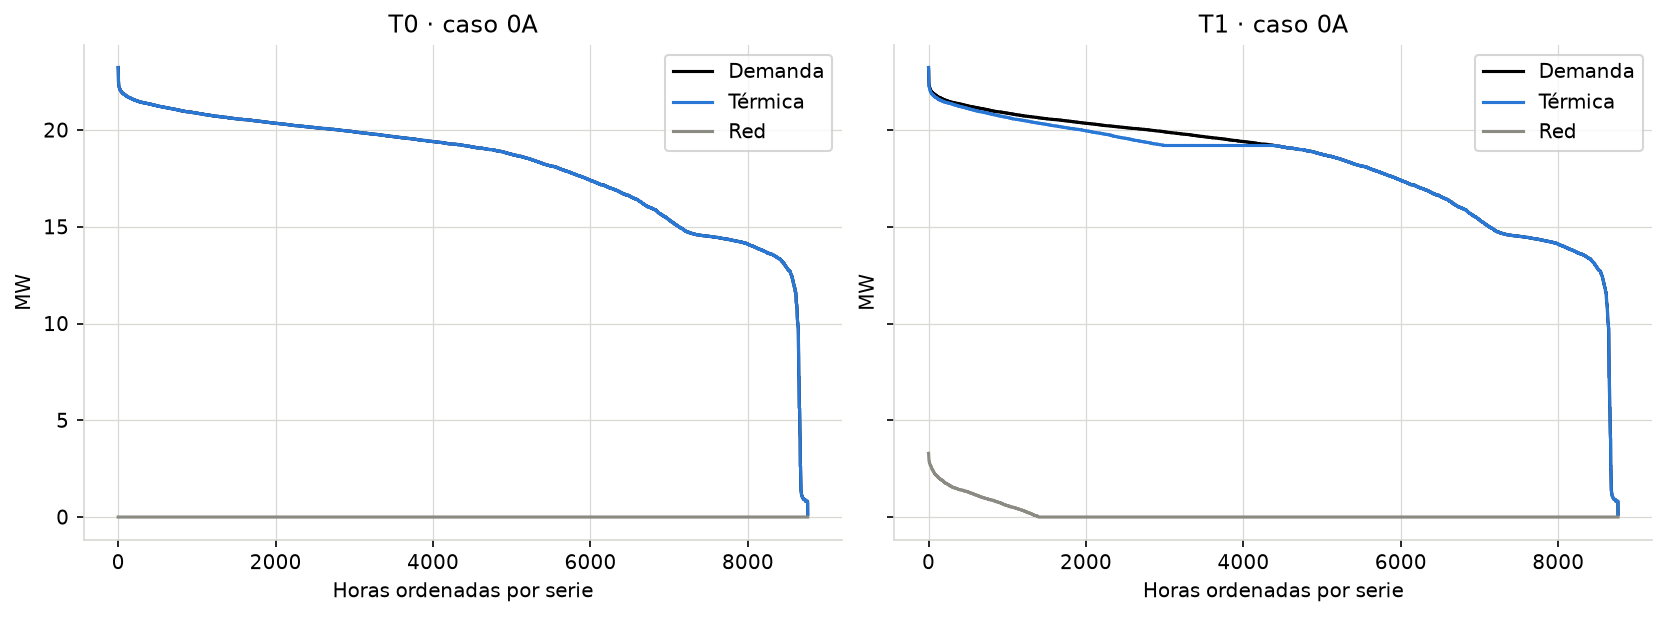

In [10]:
# Regeneración desde CSV, sin optimizar.
import runpy
runpy.run_path('.build/figuras_nb11_corregidas.py')
for nombre in ("11_1_semana_representativa", "11_2_energia_por_unidad",
               "11_3_costos_red_vs_termico", "11_4_curva_duracion"):
    display(Image(filename=str(FIG / (nombre + ".png")), width=760))

---

# Documentación del Caso 0A

## Supuestos

**Del repositorio, sin modificar.** Serie de demanda industrial depurada del
cuaderno 02 —8.760 horas, 158.742,6 MWh/año, media 18,12 MW, pico 23,23 MW—;
señales de precio de importación T0 cuasi-plana y T1 horaria indexada, en
COP/MWh; TRM congelada de `costos.py`, 3.126,08 COP/USD al 5 de septiembre de
2026.

**Declarados en este cuaderno.**

| | valor |
|---|---|
| Precio del gas | **16 USD/MMBtu** (escenario «actual») en el 0A. Los escenarios 8 y 20 se ejecutan desde el 0B (§12) |
| Costo variable adicional | 9,28 USD/MWh, igual para las cuatro unidades |
| Capacidad | la **disponible**, no la nominal: 8 + 8 + 6 + 3,2 = 25,2 MW |
| Mínimos técnicos | declarados en la tabla, **no aplicados en el 0A**; se aplican desde el 0B (§12) |
| Exportación | **no permitida** |
| Capacidad de la red | sin límite |
| Paso temporal | 1 h, sin rampas ni restricciones intertemporales |
| Desempate G1/G2 | por orden de declaración; sin efecto económico porque comparten costo marginal |

**Lo que este modelo no representa todavía:** unit commitment, arranques,
tiempos mínimos de operación, rampas, degradación, indisponibilidades forzadas,
y cualquier costo fijo de las unidades térmicas. El costo reportado es
estrictamente variable.

## Ecuaciones

**Costo marginal de cada unidad**

$$CV_g = HeatRate_g \times PrecioGas + CV^{adicional}_g \qquad [\mathrm{USD/MWh}]$$

**Balance horario**

$$Load_t = \sum_{g} P^{g}_t + P^{red}_t$$

**Límites**

$$0 \le P^{g}_t \le P^{disp}_g \qquad P^{red}_t \ge 0 \qquad \sum_g P^g_t + P^{red}_t \le Load_t$$

**Regla de despacho.** En cada hora se ordenan las cinco fuentes por costo
creciente y se llena la demanda desde la más barata. Formalmente equivale a
minimizar $\sum_t \left( \sum_g CV_g P^g_t + c^{imp}_t P^{red}_t \right)$ sujeto
a las restricciones anteriores; como no hay acoplamiento entre horas ni
variables enteras, el óptimo se obtiene hora a hora por orden de mérito, sin
necesidad de un solver.

**Consumo de combustible y costos anuales**

$$Gas_g = E_g \times HeatRate_g \qquad
Combustible_g = Gas_g \times PrecioGas \qquad
Costo^{red} = \sum_t P^{red}_t \, c^{imp}_t \Delta t$$

## Validaciones

Las ocho comprobaciones del §8 se ejecutan sobre las dos señales, con tolerancia
de 10⁻⁹:

1. balance energético horario;
2. ninguna unidad supera su potencia disponible;
3. ninguna generación es negativa;
4. importación de red no negativa;
5. generación térmica total dentro de los 25,2 MW;
6. sin exportación: el despacho nunca excede la demanda;
7. **coherencia del orden de mérito**: si una fuente despacha, todas las
   estrictamente más baratas de esa hora están saturadas;
8. la energía anual por fuente suma la demanda anual.

Además se verifican automáticamente los costos marginales contra los valores
esperados a 16 USD/MMBtu —137,28 · 137,28 · 169,28 · 138,20 USD/MWh— con
tolerancia de 0,01, y las tres magnitudes de la serie de demanda.

## Continuidad desde el checkpoint 0A

El Caso 0A anterior queda conservado como referencia. La ampliación que sigue
resuelve mínimos técnicos exactamente por hora enumerando los 16 estados,
sin restricciones intertemporales ni necesidad de montar un MILP anual.
Se comparan 0A y 0B a gas 16 y se evalúa 0B a gas 8, 16 y 20 bajo T0/T1.
La integración de PV/BESS y las demás ampliaciones quedan fuera de esta etapa.

# Caso 0B · Mínimos técnicos y sensibilidad al gas

La referencia 0A corresponde al checkpoint `6684237` y la 0B al `d65e297`.
Sus CSV y figuras se conservan **congelados**: `termica_barridos.py`
recalcula ambos casos y verifica que coincidan con esos archivos, sin
sobrescribirlos. Por eso
las figuras 11_1 a 11_6 se regeneran desde los CSV corregidos.

## 12 · Solución exacta sin acoplamiento entre horas

Se enumeran los 16 estados de las cuatro unidades físicas. Para cada estado se
descartan mínimos que excedan la demanda, se asignan los mínimos y se cubre el
residuo con capacidad incremental y red por costo marginal. El costo incluye
**toda** la generación, también la asignada a mínimos. El menor costo entre los
estados es el óptimo: cada subproblema es un despacho lineal de mérito y la
enumeración cubre todo el conjunto factible. No se fija un orden de encendido.

`despachar_hora` recibe únicamente demanda, precio de red, CV, Pmin y Pmax.
`enumerar_termico` aplica el mismo cálculo a vectores horarios para ahorrar
tiempo. Los precios son USD/MWh y las potencias MW; el costo horario es USD
para el paso de **1 h** utilizado aquí.

**Desempate:** costos iguales dentro de 1e-9 USD/h se resuelven maximizando
lexicográficamente el despacho G1, G2, G3, G4. Si el despacho coincide, se
prefieren menos unidades comprometidas, y luego G1 antes que G2 antes que G3
antes que G4. No se perturban los costos. G1 y G2 se mantienen separadas, pero
su interpretación económica se hace como bloque G1+G2.

**Alcance:** solo red y térmico, sin exportación ni vertimiento térmico, sin
costos fijos o de arranque, sin rampas ni tiempos mínimos. Se mantienen intactas
las señales T0/T1, la TRM y la dependencia `cargar_entorno_nb02()`.

In [11]:
print(DOC["enumerar_termico"])

Óptimo de horas independientes; arrays en MW y USD/MWh, paso 1 h.

Retorna potencias (cuatro unidades y red), compromiso, costo seleccionado,
costos de los 16 estados y máscara de factibilidad. No modifica los
argumentos. permitir_red=False se usa solo para el contrafactual térmico:
una hora no factible conserva costo infinito.

Desempate: costos iguales dentro de TOL_COSTO se resuelven maximizando
lexicográficamente el despacho G1, G2, G3, G4; si coincide, menos unidades
comprometidas.


In [12]:
VALIDACIONES = pd.read_csv(SAL / "caso0B_con_minimos_validaciones.csv")
display(VALIDACIONES)
display(VERIF[VERIF.Bloque.isin(["0B", "pruebas"])])

,Gas_USD_MMBtu,Senal,Residuo_balance_max_MW,Brecha_optimo_max_USD_h,Diferencia_energia_MWh,Regresion_Pmin_cero,Validacion
0,8.0,T0,3.552714e-15,1.136868e-13,0.0,OK,OK
1,8.0,T1,3.552714e-15,1.136868e-13,0.0,OK,OK
2,16.0,T0,3.552714e-15,1.136868e-13,0.0,OK,OK
3,16.0,T1,3.552714e-15,1.136868e-13,0.0,OK,OK
4,20.0,T0,3.552714e-15,2.273737e-13,0.0,OK,OK
5,20.0,T1,3.552714e-15,2.273737e-13,0.0,OK,OK


,Bloque,Control,Valor,Estado
0,pruebas,enumeracion: 18 casos; error máximo DP-MILP [USD],NaN,OK
1,pruebas,temporal: 8 casos; error máximo DP-MILP [USD],1.455192e-11,OK
2,pruebas,eventos: 15 casos; error máximo DP-MILP [USD],4.365575e-11,OK
3,pruebas,cargo: 38 casos; error máximo DP-MILP [USD],2.619345e-10,OK
9,0B,Contraste LP de estados (1206 problemas); erro...,9.094947e-13,OK
10,0B,Regresión independiente: 14 CSV de 0B iguales ...,7.450581e-09,OK


## 13 · Comparación contra 0A y sensibilidad

Se reporta costo **variable de abastecimiento**, sin CAPEX ni costos fijos.
Las horas distintas se calculan tanto por unidades físicas como por bloques
G1+G2, G4, G3 y red, para separar el efecto del reparto entre unidades gemelas.

Para distinguir competitividad de uso efectivo, se cuenta por separado:

1. horas con precio de red estrictamente menor que el CV de cada unidad;
2. horas con importación positiva;
3. horas y MWh de reducción térmica frente a un contrafactual **solo térmico
   con los mismos mínimos**, en horas donde este es factible y se importa.

El contrafactual prohíbe explícitamente la red (`permitir_red=False`),
únicamente para obtener la solución térmica cuando esta es factible;
**no cambia T0/T1** ni los escenarios. Un precio auxiliar alto no basta: una
compra pequeña puede evitar comprometer el mínimo completo de una unidad.
La imposibilidad física de operar solo con térmico se
determina por la unión de intervalos [suma Pmin, suma Pmax] de los 16 estados.
En esas horas la importación se reporta por separado y no se atribuye a una
ventaja de precio. La reducción por bloque puede combinar desplazamiento y
redistribución entre unidades; G1/G2 se atribuyen conjuntamente.

In [13]:
COMPARACION = pd.read_csv(SAL / "caso0A_sin_minimos_vs_caso0B_con_minimos.csv")
DELTAS = pd.read_csv(SAL / "caso0B_con_minimos_deltas.csv")
POR_DEMANDA = pd.read_csv(SAL / "caso0B_con_minimos_por_demanda.csv")
DETALLE = pd.read_csv(SAL / "caso0B_con_minimos_diferencias_horarias.csv")
SENSIBILIDAD = pd.read_csv(SAL / "sensibilidad_gas_resumen.csv")
DESPLAZAMIENTO = pd.read_csv(SAL / "sensibilidad_gas_desplazamiento.csv")
UMBRALES = pd.read_csv(SAL / "sensibilidad_gas_umbrales.csv")
display(COMPARACION.round(4))
display(DELTAS.round(6))
display(POR_DEMANDA.round(4))
display(SENSIBILIDAD.round(4))
display(DESPLAZAMIENTO.round(4))
display(UMBRALES.round(4))
print('Los cruces son igualdades de precio; importación efectiva requiere además demanda y factibilidad.')

,Senal,Caso,Costo_total_USD,Costo_medio_USD_MWh,Energia_termica_MWh,Energia_red_MWh,Participacion_termica_pct,Participacion_red_pct,Gas_total_MMBtu,Energia_G1_G2_MWh,Energia_G4_MWh,Energia_G3_MWh,Costo_termico_USD,Costo_red_USD,Horas_operacion_G1,Horas_operacion_G2,Horas_operacion_G3,Horas_operacion_G4
0,T0,caso0A_sin_minimos,2.196703e+07,138.3815,158742.565,0.00,100.0000,0.0000,1.280869e+06,135238.835,18574.665,4929.065,2.196703e+07,0.0000,8760,8645,4384,6749
1,T0,caso0B_con_minimos,2.203095e+07,138.7841,158086.335,656.23,99.5866,0.4134,1.276624e+06,134950.255,17678.530,5457.550,2.189303e+07,137921.1278,8669,8645,2853,6775
2,T1,caso0A_sin_minimos,2.196317e+07,138.3572,157246.675,1495.89,99.0577,0.9423,1.265910e+06,135238.835,18574.665,3433.175,2.171380e+07,249370.7081,8760,8645,2986,6749
3,T1,caso0B_con_minimos,2.200268e+07,138.6060,156621.255,2121.31,98.6637,1.3363,1.261305e+06,134953.035,18019.680,3648.540,2.163433e+07,368349.5694,8669,8645,1896,6772


,Senal,Horas_despacho_distinto,Horas_bloques_distintos,Horas_solo_reparto_G1_G2,Delta_costo_USD,Delta_costo_pct,Delta_red_MWh,Delta_gas_MMBtu,Demanda_min_cambio_MW,Demanda_max_cambio_MW
0,T0,4151,4133,18,63919.515411,0.290979,656.23,-4244.487376,0.13,20.99
1,T1,2952,2934,18,39501.409507,0.179853,625.42,-4604.597136,0.13,20.99


,Senal,Nivel_demanda_MW,Horas,Horas_distintas,Horas_bloques_distintos,Delta_costo_USD,Delta_G1_G2_MWh,Delta_G4_MWh,Delta_G3_MWh,Delta_red_MWh
0,T0,"[0.0, 0.96)",58,58,58,3601.8811,-49.28,0.000,0.000,49.28
1,T0,"[0.96, 8.0)",57,33,33,36.8087,-39.94,39.940,0.000,0.00
2,T0,"[8.0, 16.0)",1889,18,0,0.0000,0.00,0.000,0.000,0.00
3,T0,"[16.0, 19.2)",2356,461,461,188.7478,-199.36,199.290,0.000,0.07
4,T0,"[19.2, 25.2)",4400,3581,3581,60092.0779,0.00,-1135.365,528.485,606.88
5,T1,"[0.0, 0.96)",58,58,58,2384.8354,-49.28,0.000,0.000,49.28
6,T1,"[0.96, 8.0)",57,33,33,36.8087,-39.94,39.940,0.000,0.00
7,T1,"[8.0, 16.0)",1889,18,0,0.0000,0.00,0.000,0.000,0.00
8,T1,"[16.0, 19.2)",2356,461,461,187.1187,-196.58,196.410,0.000,0.17
9,T1,"[19.2, 25.2)",4400,2382,2382,36892.6467,0.00,-791.335,215.365,575.97


,Costo_total_USD,Costo_medio_USD_MWh,Energia_termica_MWh,Energia_red_MWh,Participacion_termica_pct,Participacion_red_pct,Gas_total_MMBtu,Energia_G1_G2_MWh,Energia_G4_MWh,Energia_G3_MWh,Costo_termico_USD,Costo_red_USD,Horas_operacion_G1,Horas_operacion_G2,Horas_operacion_G3,Horas_operacion_G4,Gas_USD_MMBtu,Senal,CV_G1_G2_USD_MWh,CV_G4_USD_MWh,CV_G3_USD_MWh,Horas_red_mas_barata_G1_G2,Horas_red_mas_barata_G4,Horas_red_mas_barata_G3,Horas_importacion,Horas_importacion_minimos,Energia_red_minimos_MWh,Horas_importacion_economia,Energia_red_economia_MWh
0,1.177282e+07,74.1630,158651.400,91.165,99.9426,0.0574,1.285170e+06,134943.605,16194.645,7513.15,1.175365e+07,1.917687e+04,8669,8645,3995,6782,8.0,T0,73.28,73.7408,89.28,0,0,0,447,58,49.28,389,41.885
1,1.177072e+07,74.1497,158634.570,107.995,99.9320,0.0680,1.284821e+06,134943.605,16287.615,7403.35,1.175070e+07,2.002111e+04,8669,8645,3934,6782,8.0,T1,73.28,73.7408,89.28,0,0,0,508,58,49.28,450,58.715
2,2.203095e+07,138.7841,158086.335,656.230,99.5866,0.4134,1.276624e+06,134950.255,17678.530,5457.55,2.189303e+07,1.379211e+05,8669,8645,2853,6775,16.0,T0,137.28,138.2016,169.28,0,0,0,1596,58,49.28,1538,606.950
3,2.200268e+07,138.6060,156621.255,2121.310,98.6637,1.3363,1.261305e+06,134953.035,18019.680,3648.54,2.163433e+07,3.683496e+05,8669,8645,1896,6772,16.0,T1,137.28,138.2016,169.28,0,0,3389,2556,58,49.28,2498,2072.030
4,2.709529e+07,170.6870,154809.860,3932.705,97.5226,2.4774,1.241659e+06,134953.075,18808.285,1048.50,2.626982e+07,8.254668e+05,8669,8645,485,6772,20.0,T0,169.28,170.4320,209.28,0,0,3285,3967,58,49.28,3909,3883.425
5,2.685919e+07,169.1996,97339.510,61403.055,61.3191,38.6809,7.830657e+05,83485.320,12025.740,1828.45,1.656462e+07,1.029456e+07,5310,5298,935,4479,20.0,T1,169.28,170.4320,209.28,3389,3601,5740,5553,58,49.28,5495,61353.775


,Gas_USD_MMBtu,Senal,Bloque,Horas_red_mas_barata,Horas_reduccion_con_importacion,Reduccion_positiva_MWh,Reduccion_neta_MWh
0,8.0,T0,G1_G2,0,0,0.000,0.000
1,8.0,T0,G4,0,0,0.000,-658.315
2,8.0,T0,G3,0,389,700.200,700.200
3,8.0,T1,G1_G2,0,0,0.000,0.000
4,8.0,T1,G4,0,0,0.000,-751.285
5,8.0,T1,G3,0,450,810.000,810.000
6,16.0,T0,G1_G2,0,0,0.000,-6.650
7,16.0,T0,G4,0,7,6.720,-2142.200
8,16.0,T0,G3,0,1531,2755.800,2755.800
9,16.0,T1,G1_G2,0,0,0.000,-9.430


,Senal,Bloque,Gas_primer_cruce_USD_MMBtu
0,T0,G1_G2,24.9600
1,T0,G4,24.7815
2,T0,G3,19.9680
3,T1,G1_G2,19.2428
4,T1,G4,19.1053
5,T1,G3,15.3943


Los cruces son igualdades de precio; importación efectiva requiere además demanda y factibilidad.


## 14 · Dos figuras de diagnóstico

La ventana de 48 horas se selecciona por la mayor suma de diferencias absolutas
de despacho G3 y G4 entre 0A y 0B bajo T1. Así se muestra el efecto sobre las
unidades marginales, que explica la mayor parte del sobrecosto anual.
G1+G2 se presentan como bloque; las cuatro unidades físicas se
conservan en los CSV. La sensibilidad muestra el costo medio, con etiquetas
directas de participación de red. No se añade un segundo eje.

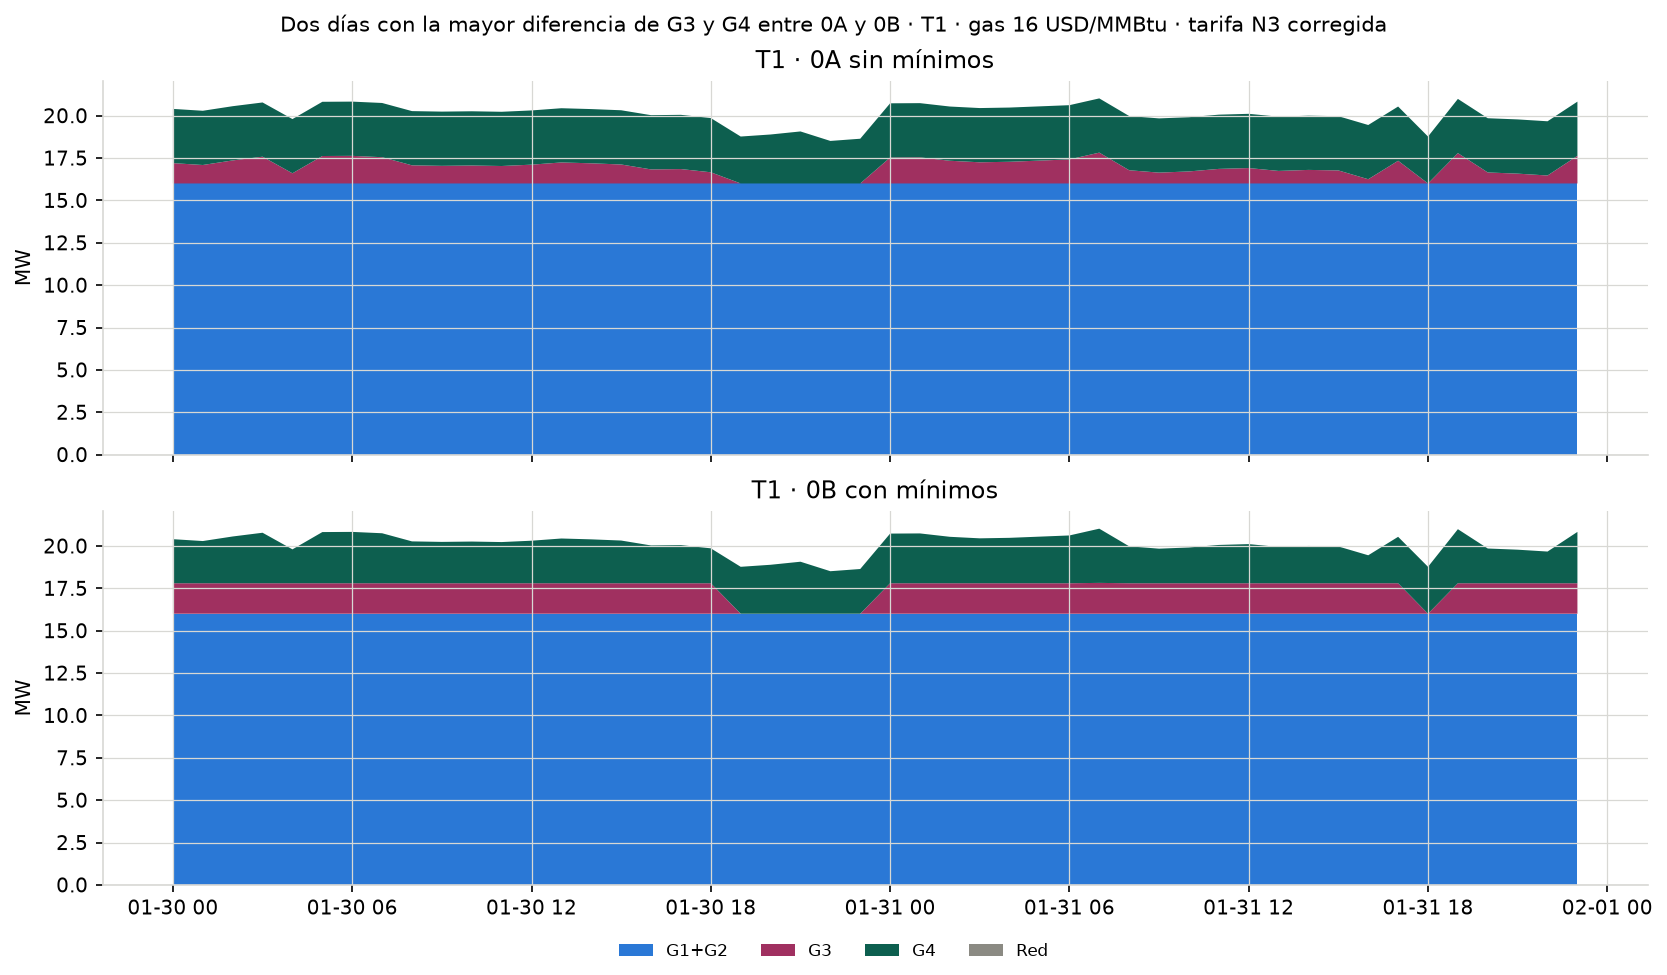

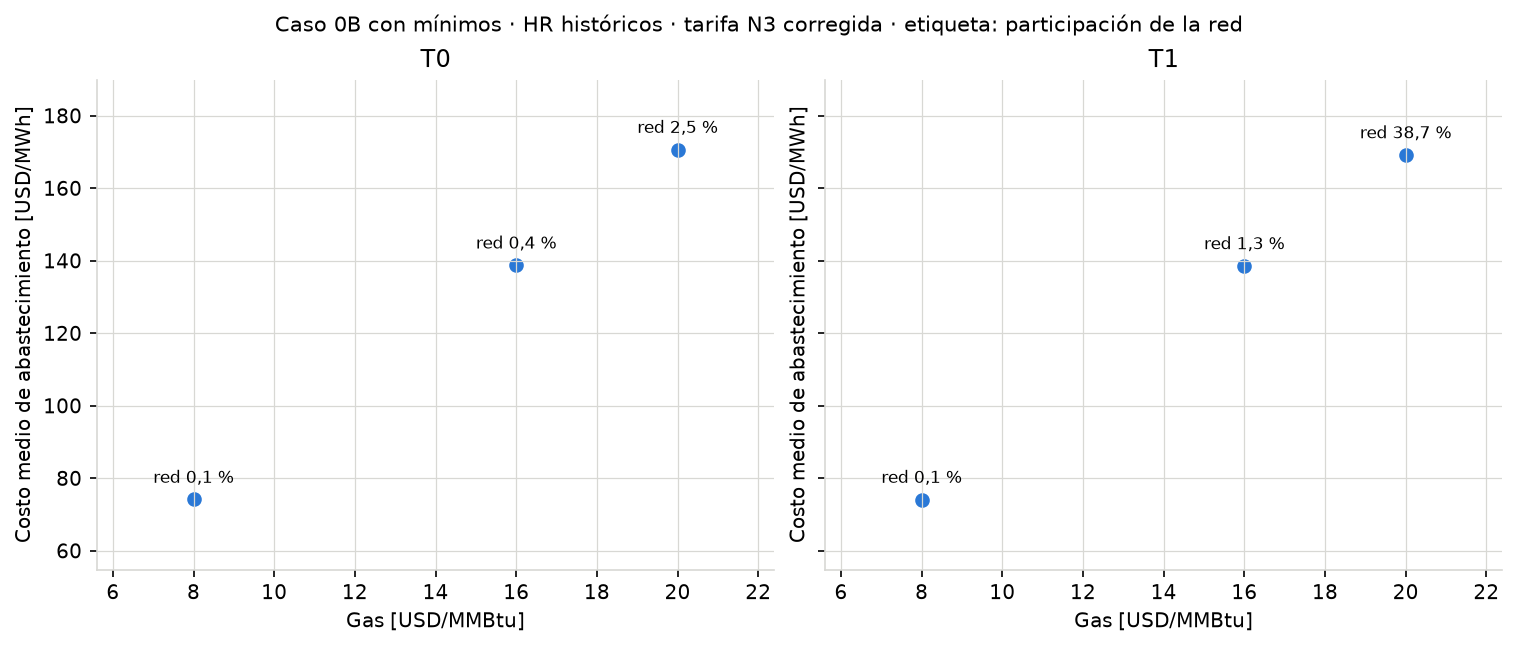

In [14]:
# Figuras 0B regeneradas desde los CSV corregidos en §10.
for nombre in ("11_5_caso0A_vs_caso0B", "11_6_sensibilidad_gas"):
    display(Image(filename=str(FIG / (nombre + ".png")), width=900))

In [15]:
# Lectura cuantitativa producida desde resultados, sin umbral de materialidad.
from IPython.display import Markdown
texto = ['## 15 · Lectura de los resultados', '']
for _,d in DELTAS.iterrows():
    texto.append(f"- **{d.Senal}, gas 16:** sobrecosto {d.Delta_costo_USD:,.2f} USD/año "
                 f"({d.Delta_costo_pct:.5f} %); {int(d.Horas_despacho_distinto)} horas "
                 f"con cambio físico, {int(d.Horas_bloques_distintos)} por bloques; "
                 f"demanda entre {d.Demanda_min_cambio_MW:.2f} y {d.Demanda_max_cambio_MW:.2f} MW.")
    tramo = DETALLE[(DETALLE.Senal==d.Senal) & (DETALLE.Demanda_MW>=19.2)]
    fraccion = 100*tramo.Delta_costo_USD.sum()/d.Delta_costo_USD
    texto.append(f"  El tramo 19,2–20,99 MW concentra {fraccion:.2f} % del sobrecosto. "
                 'Cuando el residual de G3 no alcanza 1,8 MW, conviene reducir G4 para '
                 'acomodar el mínimo de G3 o apagar G3 y comprar el residual. Por eso '
                 'G3 puede generar más energía anual y operar menos horas que en 0A.')
texto += ['', 'La potencia máxima disponible supera el pico de demanda. Sin embargo, '
          'los mínimos pueden impedir atender exclusivamente con térmico una demanda '
          'inferior al mínimo de la unidad más pequeña; esa importación no se debe a '
          'falta de capacidad máxima ni puede atribuirse exclusivamente a economía.', '']
texto += ['También puede ser óptimo importar aun si la red es más cara que todas '
          'las unidades: una compra pequeña evita comprometer un mínimo que obliga '
          'a desplazar generación más barata. Esto ocurre incluso a gas 8; comparar '
          'solo costos marginales individuales no determina el compromiso óptimo.', '']
for s in SENALES:
    d=SENSIBILIDAD.loc[SENSIBILIDAD.Senal==s].set_index('Gas_USD_MMBtu')
    texto.append(f"- **{s}:** costo anual a gas 8 / 16 / 20 = " +
                 ' / '.join(f'{d.loc[g,"Costo_total_USD"]/1e6:.6f}' for g in [8.,16.,20.])+
                 ' MUSD. Importación = '+
                 ' / '.join(f'{d.loc[g,"Energia_red_MWh"]:,.3f}' for g in [8.,16.,20.])+' MWh.')
texto += ['', '**Interpretación:** G3 es la primera unidad cuyo costo supera el de la red. '
          'A gas 20, bajo T1, también G4 y G1/G2 cruzan el precio de red en parte del año. '
          'Los cruces de costo no equivalen a horas de desplazamiento; consultar la tabla '
          'por bloque y las horas de importación condicionadas a factibilidad térmica.', '',
          '**Recomendación para decidir la etapa siguiente:** conservar la representación '
          'de mínimos como sensibilidad explícita y referencia física. Estos resultados '
          'cuantifican su efecto en red+térmico, pero no justifican todavía eliminarlos '
          'del futuro PV+BESS: la demanda residual y la posibilidad de cargar una batería '
          'cambian la factibilidad. La elección de binarias acopladas queda pendiente '
          'de esa evaluación; aquí no se implementa. Los bloques §§19–28 desarrollan '
          'después esa representación temporal.', '',
          '**Arquitectura:** las entradas siguen saliendo de '
          '`benchmark_optimo.cargar_entorno_nb02()`, ahora desde `termica.cargar_entradas()`, '
          'que usa `termica_barridos.py`. Como mejora posterior, podría añadirse a ese '
          'cargador un modo de solo entradas que ejecute las celdas de datos y tarifas '
          'del cuaderno 02 sin el cálculo solar, con regresión exacta frente al actual.']
display(Markdown('\n'.join(texto)))

## 15 · Lectura de los resultados

- **T0, gas 16:** sobrecosto 63,919.52 USD/año (0.29098 %); 4151 horas con cambio físico, 4133 por bloques; demanda entre 0.13 y 20.99 MW.
  El tramo 19,2–20,99 MW concentra 94.01 % del sobrecosto. Cuando el residual de G3 no alcanza 1,8 MW, conviene reducir G4 para acomodar el mínimo de G3 o apagar G3 y comprar el residual. Por eso G3 puede generar más energía anual y operar menos horas que en 0A.
- **T1, gas 16:** sobrecosto 39,501.41 USD/año (0.17985 %); 2952 horas con cambio físico, 2934 por bloques; demanda entre 0.13 y 20.99 MW.
  El tramo 19,2–20,99 MW concentra 93.40 % del sobrecosto. Cuando el residual de G3 no alcanza 1,8 MW, conviene reducir G4 para acomodar el mínimo de G3 o apagar G3 y comprar el residual. Por eso G3 puede generar más energía anual y operar menos horas que en 0A.

La potencia máxima disponible supera el pico de demanda. Sin embargo, los mínimos pueden impedir atender exclusivamente con térmico una demanda inferior al mínimo de la unidad más pequeña; esa importación no se debe a falta de capacidad máxima ni puede atribuirse exclusivamente a economía.

También puede ser óptimo importar aun si la red es más cara que todas las unidades: una compra pequeña evita comprometer un mínimo que obliga a desplazar generación más barata. Esto ocurre incluso a gas 8; comparar solo costos marginales individuales no determina el compromiso óptimo.

- **T0:** costo anual a gas 8 / 16 / 20 = 11.772824 / 22.030947 / 27.095287 MUSD. Importación = 91.165 / 656.230 / 3,932.705 MWh.
- **T1:** costo anual a gas 8 / 16 / 20 = 11.770721 / 22.002676 / 26.859186 MUSD. Importación = 107.995 / 2,121.310 / 61,403.055 MWh.

**Interpretación:** G3 es la primera unidad cuyo costo supera el de la red. A gas 20, bajo T1, también G4 y G1/G2 cruzan el precio de red en parte del año. Los cruces de costo no equivalen a horas de desplazamiento; consultar la tabla por bloque y las horas de importación condicionadas a factibilidad térmica.

**Recomendación para decidir la etapa siguiente:** conservar la representación de mínimos como sensibilidad explícita y referencia física. Estos resultados cuantifican su efecto en red+térmico, pero no justifican todavía eliminarlos del futuro PV+BESS: la demanda residual y la posibilidad de cargar una batería cambian la factibilidad. La elección de binarias acopladas queda pendiente de esa evaluación; aquí no se implementa. Los bloques §§19–28 desarrollan después esa representación temporal.

**Arquitectura:** las entradas siguen saliendo de `benchmark_optimo.cargar_entorno_nb02()`, ahora desde `termica.cargar_entradas()`, que usa `termica_barridos.py`. Como mejora posterior, podría añadirse a ese cargador un modo de solo entradas que ejecute las celdas de datos y tarifas del cuaderno 02 sin el cálculo solar, con regresión exacta frente al actual.

## 16 · Referencia de fabricante: unidades anonimizadas

**Escenario documental, no calibración de planta.** Se conserva el bloque
histórico 0A/0B del commit `d65e297` y se cambia únicamente la referencia de
consumo específico. No se modifican demanda, señales T0/T1, TRM, CVOM, mínimos
ni potencias disponibles. Se evalúan gas 8, 16 y 20 USD/MMBtu, con y sin mínimos.

Por confidencialidad, se usan exclusivamente los identificadores G1–G4.
En este bloque se omiten ubicación, marcas, modelos y enlaces de equipos.
Los parámetros numéricos se conservan para reproducir el cálculo: esta omisión
no garantiza anonimato frente a identificación indirecta. El bloque histórico
conserva datos anteriores. La información documental específica no se adjunta.

| Unidad | HR de referencia Btu/kWh | HR MMBtu/MWh | Potencia disponible MW |
|---|---:|---:|---:|
| G1 | 9.638 | 9,638 | 8,0 |
| G2 | 9.638 | 9,638 | 8,0 |
| G3 | 11.089 | 11,089 | 6,0 |
| G4 | 12.240 | 12,240 | 3,2 |

Consulta documental: **12 de septiembre de 2026**. Se usa la referencia de
generación eléctrica en ciclo simple y se convierte Btu/kWh a MMBtu/MWh
dividiendo por 1.000. La referencia documental aproxima las unidades; no se
afirma identidad de revisión de hardware o rendimiento en sitio. Se conserva
la columna Btu publicada sin promediar discrepancias con otras unidades.
La referencia de G4 declara PCI/LHV y ausencia de pérdidas de accesorios;
las referencias seleccionadas para G1–G3 no explicitan la base calorífica.

**Convención económica explícita:** los precios 8/16/20 se interpretan en la
misma base energética que el HR de cada referencia. No se conoce si la factura
de gas usa PCI o PCS; no se aplica un factor de conversión inventado. Los
costos son condicionales a esta compatibilidad y no constituyen una estimación
calibrada de facturación real. Tampoco se añaden pérdidas de auxiliares sin datos.

El HR es constante: no corrige temperatura, altura, degradación ni carga
parcial. Plena carga disponible en sitio no equivale necesariamente a la misma
fracción de carga nominal ISO. No se escala el HR mediante el cociente de
potencias. No se inventa consumo en vacío, curva por tramos ni una banda
porcentual de incertidumbre sin fuente. La sensibilidad de esta etapa mantiene
los tres precios de gas ya declarados.

Los mínimos se mantienen como supuestos previos, no como valores certificados
por estas fichas. El óptimo es el del modelo anual separable, sin acoplamiento
intertemporal. No representa costos de arranque, rampas ni tiempos mínimos.

In [16]:
GEN_FAB = pd.read_csv(SAL / "fabricante_parametros_fuentes.csv", index_col="Unidad")
HR_FAB = GEN_FAB.HeatRate_MMBtu_MWh.to_numpy()
np.testing.assert_allclose(HR_FAB, T.HR_FABRICANTE_BTU_KWH / 1000, rtol=0, atol=1e-12)
display(GEN_FAB[['P_disp_MW', 'P_min_MW', 'HeatRate_MMBtu_MWh', 'CV_USD_MWh']])
print('Orden térmico de referencia: G1 = G2 < G3 < G4; capacidad disponible 25,2 MW.')

,P_disp_MW,P_min_MW,HeatRate_MMBtu_MWh,CV_USD_MWh
Unidad,,,,
G1,8.0,2.40,9.638,163.488
G2,8.0,2.40,9.638,163.488
G3,6.0,1.80,11.089,186.704
G4,3.2,0.96,12.240,205.120


Orden térmico de referencia: G1 = G2 < G3 < G4; capacidad disponible 25,2 MW.


In [17]:
FAB_VALIDACIONES = pd.read_csv(SAL / "fabricante_validaciones.csv")
FAB_RESUMEN = pd.read_csv(SAL / "fabricante_resumen.csv")
display(VERIF[VERIF.Bloque == "fabricante"])
display(FAB_VALIDACIONES)
display(FAB_RESUMEN[['Caso', 'Gas_USD_MMBtu', 'Senal', 'Costo_total_USD', 'Costo_medio_USD_MWh',
                     'Energia_termica_MWh', 'Energia_red_MWh', 'Participacion_red_pct',
                     'Energia_G1_G2_MWh', 'Energia_G3_MWh', 'Energia_G4_MWh']].round(4))

,Bloque,Control,Valor,Estado
11,fabricante,Contraste LP de estados (1295 problemas); erro...,1.818989e-12,OK
12,fabricante,Doce escenarios validados; 18 CSV escritos,NaN,OK


,Gas_USD_MMBtu,Senal,Caso,Residuo_balance_max_MW,Brecha_optimo_max_USD_h,Diferencia_energia_MWh,Estado
0,8.0,T0,0A,0.000000e+00,0.000000e+00,0.0,OK
1,8.0,T0,0B,3.552714e-15,1.136868e-13,0.0,OK
2,8.0,T1,0A,0.000000e+00,0.000000e+00,0.0,OK
3,8.0,T1,0B,3.552714e-15,1.136868e-13,0.0,OK
4,16.0,T0,0A,0.000000e+00,0.000000e+00,0.0,OK
5,16.0,T0,0B,3.552714e-15,0.000000e+00,0.0,OK
6,16.0,T1,0A,3.552714e-15,0.000000e+00,0.0,OK
7,16.0,T1,0B,3.552714e-15,0.000000e+00,0.0,OK
8,20.0,T0,0A,3.552714e-15,0.000000e+00,0.0,OK
9,20.0,T0,0B,1.776357e-15,2.273737e-13,0.0,OK


,Caso,Gas_USD_MMBtu,Senal,Costo_total_USD,Costo_medio_USD_MWh,Energia_termica_MWh,Energia_red_MWh,Participacion_red_pct,Energia_G1_G2_MWh,Energia_G3_MWh,Energia_G4_MWh
0,0A,8.0,T0,1.398573e+07,88.1032,158742.565,0.000,0.0000,135238.835,23494.490,9.24
1,0B,8.0,T0,1.400119e+07,88.2006,158687.845,54.720,0.0345,134808.265,23402.280,477.30
2,0A,8.0,T1,1.398573e+07,88.1032,158742.565,0.000,0.0000,135238.835,23494.490,9.24
3,0B,8.0,T1,1.399988e+07,88.1923,158685.915,56.650,0.0357,134812.405,23404.850,468.66
4,0A,16.0,T0,2.649834e+07,166.9265,158742.565,0.000,0.0000,135238.835,23494.490,9.24
5,0B,16.0,T0,2.651305e+07,167.0191,158507.535,235.030,0.1481,134949.315,23418.840,139.38
6,0A,16.0,T1,2.631571e+07,165.7760,147040.910,11701.655,7.3715,134666.165,12368.855,5.89
7,0B,16.0,T1,2.632594e+07,165.8405,146873.705,11868.860,7.4768,134428.255,12280.250,165.20
8,0A,20.0,T0,3.226495e+07,203.2533,135238.835,23503.730,14.8062,135238.835,0.000,0.00
9,0B,20.0,T0,3.226568e+07,203.2579,135149.615,23592.950,14.8624,135149.615,0.000,0.00


## 17 · Separar efecto del HR y efecto de mínimos

La tabla compara **fabricante 0B contra histórico 0B**, manteniendo los mismos
precios y límites, para aislar el cambio de HR. Se muestra aparte **fabricante
0B contra fabricante 0A** para medir los mínimos bajo el nuevo orden de mérito.
Las diferencias de despacho se cuentan por unidades y por bloques G1+G2/G4/G3/red.

Para el desplazamiento efectivo se conserva la definición del §13: reducción
frente al óptimo solo térmico, sin red y con los mismos mínimos, en horas
factibles e importadoras. No se equipara un cruce de precio con uso de red.

In [18]:
FAB_COMPARACION = pd.read_csv(SAL / "fabricante_comparacion.csv")
FAB_DESPLAZAMIENTO = pd.read_csv(SAL / "fabricante_desplazamiento.csv")
FAB_UMBRALES = pd.read_csv(SAL / "fabricante_umbrales.csv")
display(FAB_COMPARACION.round(4))
display(FAB_DESPLAZAMIENTO.round(4))
display(FAB_UMBRALES.round(4))

,Gas_USD_MMBtu,Senal,Costo_historico_0B_USD,Costo_fabricante_0A_USD,Costo_fabricante_0B_USD,Delta_HR_costo_USD,Delta_HR_costo_pct,Delta_HR_red_MWh,Delta_HR_gas_MMBtu,Delta_minimos_costo_USD,Delta_minimos_costo_pct,Delta_minimos_red_MWh,Horas_cambio_minimos,Horas_cambio_bloques,Demanda_min_cambio_MW,Demanda_max_cambio_MW
0,8.0,T0,1.177282e+07,1.398573e+07,1.400119e+07,2.228366e+06,18.9280,-36.445,279461.7814,15456.2260,0.1105,54.720,1141,1123,0.13,22.63
1,8.0,T1,1.177072e+07,1.398573e+07,1.399988e+07,2.229157e+06,18.9382,-51.345,279773.3128,14144.2023,0.1011,56.650,1141,1123,0.13,22.63
2,16.0,T0,2.203095e+07,2.649834e+07,2.651305e+07,4.482098e+06,20.3446,-421.200,285414.9626,14707.8944,0.0555,235.030,1141,1123,0.13,22.63
3,16.0,T1,2.200268e+07,2.631571e+07,2.632594e+07,4.323265e+06,19.6488,9747.550,172512.2084,10229.1899,0.0389,167.205,760,742,0.13,22.63
4,20.0,T0,2.709529e+07,3.226495e+07,3.226568e+07,5.170397e+06,19.0823,19660.245,60912.7522,731.9272,0.0023,89.220,109,91,0.13,10.33
5,20.0,T1,2.685919e+07,2.955232e+07,2.955796e+07,2.698777e+06,10.0479,38507.555,-207703.5960,5643.7562,0.0191,66.380,310,300,0.72,22.38


,Gas_USD_MMBtu,Senal,Bloque,Horas_red_mas_barata,Horas_reduccion_con_importacion,Reduccion_positiva_MWh,Reduccion_neta_MWh
0,8.0,T0,G1_G2,0,0,0.000,-61.10
1,8.0,T0,G4,0,78,74.880,74.88
2,8.0,T0,G3,0,0,0.000,-8.34
3,8.0,T1,G1_G2,0,0,0.000,-65.24
4,8.0,T1,G4,0,87,83.520,83.52
5,8.0,T1,G3,0,0,0.000,-10.91
6,16.0,T0,G1_G2,0,0,0.000,-202.15
7,16.0,T0,G4,0,430,412.800,412.80
8,16.0,T0,G3,0,0,0.000,-24.90
9,16.0,T1,G1_G2,37,37,568.290,318.91


,Senal,Bloque,Gas_primer_cruce_USD_MMBtu
0,T0,G1_G2,20.7180
1,T0,G3,18.0070
2,T0,G4,16.3137
3,T1,G1_G2,15.9725
4,T1,G3,13.8825
5,T1,G4,12.5770


In [19]:
lectura_fab = ['## 18 · Lectura del escenario documental','',
              '**Orden térmico:** G1/G2 → G3 → G4. G4 es ahora la '
              'unidad térmica más cara. La red se inserta hora a hora según T0/T1.','']
for _,r in FAB_COMPARACION[FAB_COMPARACION.Gas_USD_MMBtu==16].iterrows():
    fila = FAB_RESUMEN[(FAB_RESUMEN.Gas_USD_MMBtu==16)&(FAB_RESUMEN.Senal==r.Senal)&(FAB_RESUMEN.Caso=='0B')].iloc[0]
    lectura_fab.append(f'- **{r.Senal}, gas 16, con mínimos:** costo {r.Costo_fabricante_0B_USD/1e6:.6f} '
                      f'MUSD/año; red {fila.Participacion_red_pct:.3f} %. '
                      f'El cambio de HR suma {r.Delta_HR_costo_USD:,.2f} USD '
                      f'({r.Delta_HR_costo_pct:.3f} %) frente al 0B histórico. '
                      f'Los mínimos suman {r.Delta_minimos_costo_USD:,.2f} USD '
                      f'({r.Delta_minimos_costo_pct:.5f} %) frente al 0A fabricante; '
                      f'cambian {int(r.Horas_cambio_minimos)} horas físicas y '
                      f'{int(r.Horas_cambio_bloques)} horas por bloques.')
for _,r in FAB_COMPARACION[FAB_COMPARACION.Gas_USD_MMBtu!=16].iterrows():
    fila = FAB_RESUMEN[(FAB_RESUMEN.Gas_USD_MMBtu==r.Gas_USD_MMBtu)&(FAB_RESUMEN.Senal==r.Senal)&(FAB_RESUMEN.Caso=='0B')].iloc[0]
    lectura_fab.append(f'- **{r.Senal}, gas {r.Gas_USD_MMBtu:.0f}, con mínimos:** costo '
                      f'{r.Costo_fabricante_0B_USD/1e6:.3f} MUSD/año; red {fila.Participacion_red_pct:.2f} %; '
                      f'G3 {fila.Energia_G3_MWh:,.0f} MWh y G4 {fila.Energia_G4_MWh:,.0f} MWh.')
# Fragilidad del cruce entre G1/G2 y el piso de T1: se mide, no se barre.
piso_t1 = float(C_IMP_USD['T1'].min())
cv_g1_16 = float(HR_FAB[0]*16+CVOM[0])
margen_g1 = 100*(cv_g1_16/piso_t1-1)
horas_bajo_g1 = int((C_IMP_USD['T1'] < cv_g1_16).sum())
horas_cerca_g1 = int(((C_IMP_USD['T1'] >= cv_g1_16) & (C_IMP_USD['T1'] <= 1.05*cv_g1_16)).sum())
lectura_fab += ['', f'**Fragilidad del resultado T1 a gas 16.** El CV de G1/G2 ({cv_g1_16:.2f} USD/MWh) '
                f'queda solo {margen_g1:.2f} % por encima del piso de T1 ({piso_t1:.2f} USD/MWh). '
                f'La red ya es más barata que G1/G2 en {horas_bajo_g1} h, y otras {horas_cerca_g1} h '
                'tienen un precio entre ese CV y un 5 % por encima. Una variación de ese orden que '
                'encarezca el térmico o abarate la red —TRM, base calorífica del gas o CVOM— puede '
                f'cambiar de régimen hasta {horas_cerca_g1} horas más. Se mantiene la TRM vigente, por '
                'decisión del 12/09/2026, y la convención de misma base calorífica del §16, porque no '
                'se dispone del poder calorífico facturado ni de una vía para obtenerlo. Ambas quedan '
                'como **limitaciones declaradas**, no como sensibilidades ejecutadas.']
lectura_fab += ['', 'Las conclusiones del bloque histórico, incluido su orden de mérito '
                'y el tramo de demanda dominante, corresponden a sus HR originales. '
                'No se trasladan automáticamente al escenario de fabricante.', '',
                '**Límite de interpretación:** los resultados son condicionales a HR '
                'constantes de referencia y precio de gas en base compatible. No son '
                'una curva calibrada de planta. La incertidumbre de carga parcial, '
                'condiciones ambientales y base de facturación permanece sin cuantificar '
                'por falta de información; no se sustituye por porcentajes arbitrarios.']
display(Markdown('\n'.join(lectura_fab)))

## 18 · Lectura del escenario documental

**Orden térmico:** G1/G2 → G3 → G4. G4 es ahora la unidad térmica más cara. La red se inserta hora a hora según T0/T1.

- **T0, gas 16, con mínimos:** costo 26.513045 MUSD/año; red 0.148 %. El cambio de HR suma 4,482,097.79 USD (20.345 %) frente al 0B histórico. Los mínimos suman 14,707.89 USD (0.05550 %) frente al 0A fabricante; cambian 1141 horas físicas y 1123 horas por bloques.
- **T1, gas 16, con mínimos:** costo 26.325941 MUSD/año; red 7.477 %. El cambio de HR suma 4,323,265.12 USD (19.649 %) frente al 0B histórico. Los mínimos suman 10,229.19 USD (0.03887 %) frente al 0A fabricante; cambian 760 horas físicas y 742 horas por bloques.
- **T0, gas 8, con mínimos:** costo 14.001 MUSD/año; red 0.03 %; G3 23,402 MWh y G4 477 MWh.
- **T1, gas 8, con mínimos:** costo 14.000 MUSD/año; red 0.04 %; G3 23,405 MWh y G4 469 MWh.
- **T0, gas 20, con mínimos:** costo 32.266 MUSD/año; red 14.86 %; G3 0 MWh y G4 0 MWh.
- **T1, gas 20, con mínimos:** costo 29.558 MUSD/año; red 62.94 %; G3 5,623 MWh y G4 69 MWh.

**Fragilidad del resultado T1 a gas 16.** El CV de G1/G2 (163.49 USD/MWh) queda solo 0.16 % por encima del piso de T1 (163.22 USD/MWh). La red ya es más barata que G1/G2 en 37 h, y otras 3669 h tienen un precio entre ese CV y un 5 % por encima. Una variación de ese orden que encarezca el térmico o abarate la red —TRM, base calorífica del gas o CVOM— puede cambiar de régimen hasta 3669 horas más. Se mantiene la TRM vigente, por decisión del 12/09/2026, y la convención de misma base calorífica del §16, porque no se dispone del poder calorífico facturado ni de una vía para obtenerlo. Ambas quedan como **limitaciones declaradas**, no como sensibilidades ejecutadas.

Las conclusiones del bloque histórico, incluido su orden de mérito y el tramo de demanda dominante, corresponden a sus HR originales. No se trasladan automáticamente al escenario de fabricante.

**Límite de interpretación:** los resultados son condicionales a HR constantes de referencia y precio de gas en base compatible. No son una curva calibrada de planta. La incertidumbre de carga parcial, condiciones ambientales y base de facturación permanece sin cuantificar por falta de información; no se sustituye por porcentajes arbitrarios.

## 19 · Caso 0C: compromiso temporal y límite diario

Se conserva el 0B documental como referencia. Se mantienen sus precios, HR,
demanda, mínimos técnicos y capacidades, y se añade exclusivamente memoria
operativa. Se resuelve gas 8/16/20 con T0/T1 para estos casos:

| Caso | Arranques y paradas | Permanencia mínima encendida / apagada |
|---|---|---|
| 0B | Sin límite temporal | Una hora por resolución de datos |
| 0C diario | Máximo un arranque y una parada por unidad y día calendario | Una hora por resolución de datos |
| 0C diario + 2 h | Mismo límite diario | Dos horas / dos horas, sensibilidad ilustrativa |

**Fuente del límite diario:** recuerdo de una comunicación del cliente,
transmitido por el usuario el 12/09/2026; no es una especificación certificada.
Se interpreta por unidad, no como un único arranque para toda la planta.
No obliga a arrancar o parar cada día. Las dos horas son un supuesto de
sensibilidad, no un tiempo deducido de una ficha ni un requisito real conocido.

Un evento se asigna a la fecha de la hora que comienza. El límite por día
calendario permite eventos cercanos a ambos lados de medianoche: se reporta
también el máximo en 24 horas móviles, sin imponerle un límite adicional.

**Fronteras:** el estado inicial es **libre**. El 1 de enero continúa una
operación anterior: la primera hora puede tomar cualquier compromiso, sin contar
ni cobrar arranques y con las permanencias cumplidas. Es simétrico con el
cierre, donde tampoco se fuerza una parada. No se reinicia el compromiso ni la
duración al cambiar de día. Al cierre se exige haber cumplido la permanencia,
sin imponer apagado final ni sumar una parada fuera del año. No es una
condición periódica. La frontera libre es decisión del usuario del 12/09/2026;
las funciones conservan la opción de estado inicial apagado para regresión.

**Método:** programación dinámica exacta sobre los 16 compromisos, ampliando
el estado con duración y eventos diarios de cada unidad. El costo de cada
compromiso se reutiliza de la enumeración validada del 0B. Una transformación
por unidad calcula el mínimo sobre predecesores, y después se suma el costo
del compromiso completo. La reconstrucción conserva la trayectoria anual.
Con igualdad numérica de costo se prefieren menos arranques, sin monetizarlos.

**Límite de alcance del método.** La programación dinámica solo admite
permanencias de 1 o 2 horas. Con 3 horas el espacio de estados llega a
18⁴ = 104.976, más de lo que indexa `uint16`, y la memoria del historial crece
en la misma proporción. Si aparece un tiempo mínimo real de 4 a 8 horas para
las unidades grandes, este método no escala: habrá que usar un MILP por
ventanas, del que el contraste de §21 ya es el esqueleto.

El cálculo usa la serie anual conocida como comparación retrospectiva; no es
una política causal ni una predicción de resultados operativos futuros. El
acoplamiento temporal sí aprovecha información posterior. No se añade un módulo
de previsión, rolling horizon, PV/BESS ni un MILP anual. Los MILP cortos se usan
solo como contraste independiente de la solución.

## 20 · Arranques y mantenimiento: alcance de la evidencia

Revisión documental realizada el **12/09/2026**, sin publicar identificadores
de equipos ni enlaces que permitan asociarlos a esta instalación.

| Referencia consultada | Hallazgo útil | Lo que no permite concluir |
|---|---|---|
| Fichas resumidas asociadas a G1/G2 y G3 | Presentan rendimiento y características nominales | No establecen en esas fichas un máximo de un arranque diario, permanencias mínimas ni una conversión aplicable arranque → horas equivalentes |
| Ficha resumida asociada a G4 | Describe el sistema de arranque y servicios auxiliares | No publica en esa ficha el límite diario ni la penalización de mantenimiento por evento |
| Documentación pública complementaria de servicio | Relaciona mantenimiento o degradación con perfil operativo y eventos | No certifica coeficientes para la revisión instalada ni el contrato de mantenimiento del caso |

Por tanto, **ausencia en la ficha resumida no significa ausencia de límites en
los manuales o contratos**. Tampoco la capacidad de arranque rápido equivale a
que un régimen de ciclado frecuente sea económicamente conveniente.

El término «horómetro de mantenimiento» debe distinguirse del contador de horas
reales encendido. Los intervalos pueden depender de horas equivalentes y de
arranques o ciclos equivalentes. Como respaldo general, el estudio técnico de
[AEMO, revisión de costos y parámetros, sección 4.2.2](https://aemo.com.au/-/media/Files/Electricity/NEM/Planning_and_Forecasting/Inputs-Assumptions-Methodologies/2019/9110715-REP-A-Cost-and-Technical-Parameter-Review---Rev-4-Final.pdf)
describe horas operadas más contribuciones por eventos; el
[estudio publicado por EIA para AEO2025](https://www.eia.gov/analysis/studies/powerplants/capitalcost/pdf/capital_cost_AEO2025.pdf)
describe criterios de mantenimiento por horas equivalentes y arranques
equivalentes. Consulta de ambas referencias: 12/09/2026. Son referencias
generales y no identifican ni certifican los equipos de esta instalación.

No se aplica una equivalencia numérica por arranque o parada; un ejemplo de
degradación publicado para otra configuración no basta para programar una
revisión mayor de este caso. También se evita contar dos veces un mismo ciclo
como arranque y parada cuando el fabricante usa un único factor por ciclo.
Se exportan por separado horas reales, arranques, paradas y duraciones. Los
costos reportados siguen siendo combustible + CVOM + red, sin monetizar
mantenimiento adicional por ciclado ni predecir fechas de revisión mayor.

**Confidencialidad:** omitir nombres y ubicación reduce identificación directa,
pero las combinaciones de parámetros exactos conservan riesgo de identificación
indirecta. Este cuaderno de investigación no equivale a una versión aprobada
para difusión externa. No se alteran cifras ni se reescribe el historial.

In [20]:
for nombre in ("resolver_compromiso_temporal", "rearranques_tras_demanda_baja"):
    print("termica.{}\n{}\n".format(nombre, DOC[nombre]))

termica.resolver_compromiso_temporal
DP exacta del modelo horario, con costos fijos por compromiso.

Estado local: (encendido, duración saturada, arranques hoy, paradas hoy).
Las transiciones se factorizan por unidad; el costo horario acopla las cuatro.
Inicial 'libre': la primera hora toma cualquier compromiso sin evento y con
permanencias cumplidas. Con un vector de cuatro binarios, ese es el estado
previo y los cambios de la primera hora cuentan. Terminal: permanencia
cumplida, sin exigir apagado ni inventar una parada fuera del horizonte.
Desempate: menos arranques, sin penalización monetaria artificial.

Solo admite permanencias de 1 o 2 h: con 3 h el espacio llega a 18**4
estados, más de lo que indexa uint16.

termica.rearranques_tras_demanda_baja
Diagnóstico descriptivo: rearranques tras horas de demanda menor que Pmin, por unidad.

Sin exportación, una demanda menor que el Pmin de una unidad la obliga a
**estar apagada** en esa hora. Eso solo obliga a una **parada** si estaba
e

## 21 · Verificación y resultados temporales

Se contrasta la programación dinámica con un MILP independiente de potencia,
compromiso, arranques y paradas en dos horizontes sintéticos que incluyen
medianoche, demanda baja y cruces de costo. Se comprueba también que al retirar
el límite temporal con permanencia de una hora se recupera el costo del 0B.
En el año completo se validan balance, límites, eventos diarios, permanencias
y fronteras; la jerarquía de costos se verifica para cada precio de gas y señal.

Los CSV `temporal_*` contienen doce despachos 0C y tablas de comparación con
0B, eventos por día, rachas (con censura de fronteras) y validaciones. Con
estado inicial libre no hay evento en la primera hora; el MILP de contraste usa
la misma frontera y además se prueba la frontera apagada. Las figuras nuevas llevan
el prefijo `11_temporal_`; los resultados históricos no se sustituyen.

In [21]:
TEMP_PRUEBAS = pd.read_csv(SAL / "temporal_contraste_milp.csv")
display(TEMP_PRUEBAS)
print("termica.contraste_milp_compromiso\n" + DOC["contraste_milp_compromiso"])

,Prueba,Minimo_h,Inicial,Error_DP_MILP_USD,Estado
0,cambios_y_minima,1,libre,3.637979e-12,OK
1,cambios_y_minima,1,apagado,3.637979e-12,OK
2,cambios_y_minima,2,libre,3.637979e-12,OK
3,cambios_y_minima,2,apagado,3.637979e-12,OK
4,dos_dias,1,libre,1.455192e-11,OK
5,dos_dias,1,apagado,1.455192e-11,OK
6,dos_dias,2,libre,1.455192e-11,OK
7,dos_dias,2,apagado,1.455192e-11,OK


termica.contraste_milp_compromiso
Contraste independiente: formulación de potencia/u/arranque/parada con HiGHS.

Variables por hora: cuatro potencias, red, cuatro u, cuatro arranques y y
cuatro paradas z. Con inicial_libre la primera hora no tiene evento ni enlace
con un estado previo; si no, el estado previo es apagado. El despacho continuo
se recalcula con las binarias fijadas, para no confundir tolerancias de
factibilidad del MILP con diferencias de costo. Solo para horizontes cortos.


In [22]:
TEMP_RESUMEN = pd.read_csv(SAL/'temporal_resumen.csv')
TEMP_CICLOS = pd.read_csv(SAL/'temporal_ciclado.csv')
display(TEMP_RESUMEN[['Caso','Gas_USD_MMBtu','Senal','Costo_total_USD','Delta_costo_vs_0B_USD',
                     'Participacion_red_pct','Arranques','Paradas','Encendidos_completos_1h']].round(4))
display(TEMP_CICLOS[(TEMP_CICLOS.Gas_USD_MMBtu==16)&(TEMP_CICLOS.Senal=='T1')])

# Figuras nuevas; las seis figuras anteriores permanecen congeladas.
fig,axs = plt.subplots(1,2,figsize=(12,4.6),sharey=True,layout='constrained')
casos = ['0B','0C_diario','0C_diario_2h']
etiquetas = ['0B','0C diario','0C diario + 2 h']
for ax,s in zip(axs,SENALES):
    for caso,label,marker in zip(casos,etiquetas,['o','s','^']):
        sub = TEMP_RESUMEN[(TEMP_RESUMEN.Caso==caso)&(TEMP_RESUMEN.Senal==s)]
        # Solo marcadores: tres precios de gas no justifican interpolar.
        ax.plot(sub.Gas_USD_MMBtu,sub.Arranques,label=label,color='#52514e',
                marker=marker,linestyle='None',markersize=7)
    ax.set(title=s,xlabel='Gas [USD/MMBtu, base compatible]',ylabel='Arranques anuales, cuatro unidades',xticks=[8,16,20])
    ax.grid(alpha=.2); ax.legend()
fig.savefig(FIG/'11_temporal_arranques.png',dpi=160)
plt.show()

# Mostrar el segmento donde el caso 0B tiene más transiciones (ventana de siete días).
ref = pd.read_csv(SAL/'fabricante_0B_gas16_T1.csv')[[f'u_{x}' for x in T.UNIDADES]].to_numpy()
eventos = np.abs(np.diff(ref,axis=0,prepend=ref[:1])).sum(axis=1)
fin = int(np.argmax(np.convolve(eventos,np.ones(168),mode='valid')))+168
ini = fin-168
fig,axs = plt.subplots(3,1,figsize=(13,6.5),sharex=True,layout='constrained')
for ax,caso,label in zip(axs,casos,etiquetas):
    u = ref if caso=='0B' else pd.read_csv(SAL/f'temporal_{caso}_gas16_T1.csv')[[f'u_{x}' for x in T.UNIDADES]].to_numpy()
    ax.imshow(u[ini:fin].T,aspect='auto',interpolation='nearest',origin='lower',
              cmap='Greys',vmin=0,vmax=1,extent=[0,168,-.5,3.5])
    ax.set_yticks(range(4),['G1','G2','G3','G4'])
    ax.set_title(label+' — negro: encendida; blanco: apagada',fontsize=10)
axs[-1].set_xticks(np.arange(0,169,24),[(FECHA[ini]+pd.Timedelta(hours=int(h))).strftime('%d/%m') for h in range(0,169,24)])
axs[-1].set_xlabel('Semana con más transiciones en 0B; T1, gas 16')
fig.savefig(FIG/'11_temporal_compromiso_semana.png',dpi=160)
plt.show()

texto_temporal = ['## 22 · Lectura del Caso 0C','',
    'El año empieza con estado inicial libre: la primera hora no cuenta arranques. '
    'No se añade una parada ficticia al final. Los **rearranques tras demanda baja** '
    'son un diagnóstico descriptivo: arranques después de una parada que incluye horas '
    'con demanda menor que el mínimo técnico. Dependen de la trayectoria y no indican '
    'arranques inevitables (definición en §26).','']
for s in SENALES:
    b = TEMP_RESUMEN[(TEMP_RESUMEN.Caso=='0B')&(TEMP_RESUMEN.Gas_USD_MMBtu==16)&(TEMP_RESUMEN.Senal==s)].iloc[0]
    c = TEMP_RESUMEN[(TEMP_RESUMEN.Caso=='0C_diario_2h')&(TEMP_RESUMEN.Gas_USD_MMBtu==16)&(TEMP_RESUMEN.Senal==s)].iloc[0]
    texto_temporal.append(f'- **{s}, gas 16, límite diario y permanencia 2 h:** '
        f'{int(b.Arranques)} → {int(c.Arranques)} arranques '
        f'({int(c.Rearranques_tras_demanda_baja)} rearranques tras demanda baja); '
        f'{int(b.Encendidos_completos_1h)} → {int(c.Encendidos_completos_1h)} encendidos completos de 1 h. '
        f'Costo {c.Costo_total_USD/1e6:.6f} MUSD/año, '
        f'incremento {c.Delta_costo_vs_0B_USD:,.2f} USD ({c.Delta_costo_vs_0B_pct:.4f} %); '
        f'red {c.Participacion_red_pct:.4f} %.')
ref_0b = TEMP_RESUMEN[TEMP_RESUMEN.Caso=='0B'].set_index(['Gas_USD_MMBtu','Senal'])
ref_2h = TEMP_RESUMEN[TEMP_RESUMEN.Caso=='0C_diario_2h'].set_index(['Gas_USD_MMBtu','Senal'])
con_ciclado = ref_0b.Arranques > 0
reduccion_2h = 100*(1-ref_2h.Arranques[con_ciclado]/ref_0b.Arranques[con_ciclado])
ciclo_20 = TEMP_CICLOS[(TEMP_CICLOS.Gas_USD_MMBtu==20)&(TEMP_CICLOS.Senal=='T1')
                       &(TEMP_CICLOS.Caso=='0C_diario_2h')].set_index('Unidad')
arr_g12_20 = int(ciclo_20.loc[['G1','G2'],'Arranques'].sum())
rearr_g12_20 = int(ciclo_20.loc[['G1','G2'],'Rearranques_tras_demanda_baja'].sum())
texto_temporal += ['',
    f'**Imponer los límites cuesta poco.** En las seis combinaciones de gas y señal, el '
    f'0C diario + 2 h eleva el costo como máximo {ref_2h.Delta_costo_vs_0B_pct.max():.3f} % '
    f'frente al 0B y reduce los arranques entre {reduccion_2h.min():.0f} % y '
    f'{reduccion_2h.max():.0f} %. Buena parte del ciclado del 0B era casi indiferente en '
    'costo: el óptimo horario elegía entre compromisos de costo muy parecido.', '',
    f'**Ciclado de las unidades base a gas 20 con T1.** Aun con límite diario y '
    f'permanencia de 2 h, G1+G2 suman {arr_g12_20} arranques al año; {rearr_g12_20} de ellos '
    'son rearranques tras horas de demanda menor que Pmin, que también dependen de la '
    'trayectoria elegida. El resto sigue el ciclo diario del precio de T1: las unidades '
    'base se apagan cuando la red es más barata. Sin costo de arranque, dos horas de '
    'permanencia no bastan para evitarlo (§§26–28).', '',
    'El límite diario solo no equivale a una permanencia mínima de dos horas. '
    'Tampoco equivale a limitar un arranque en cualquier ventana móvil de 24 h; '
    'la columna correspondiente muestra esta distinción. Las duraciones se '
    'transportan entre días, sin reiniciar el estado a medianoche.', '',
    'La cota 0B ≤ 0C diario ≤ 0C diario + 2 h se verifica en cada combinación '
    'gas/señal para el mismo costo variable. La reducción de arranques no se '
    'traduce aquí en ahorro monetario de mantenimiento ni en horas equivalentes '
    'evitadas: faltan factores específicos y condiciones contractuales.', '',
    'El caso temporal mejora la representación del compromiso, pero no certifica '
    'operabilidad de planta: mantiene pendientes rampas, transitorios, consumo '
    'de arranque y curva a carga parcial. La TRM y la base calorífica del gas se '
    'mantienen como en §16 y §18; el 0C no resuelve esa incertidumbre. G1 y G2 son '
    'económicamente idénticas: su reparto individual depende del desempate y se '
    'interpreta como bloque.']
display(Markdown('\n'.join(texto_temporal)))

,Caso,Gas_USD_MMBtu,Senal,Costo_total_USD,Delta_costo_vs_0B_USD,Participacion_red_pct,Arranques,Paradas,Encendidos_completos_1h
0,0B,8.0,T0,1.400119e+07,0.0000,0.0345,588,588,183
1,0C_diario,8.0,T0,1.401285e+07,11655.4547,0.0863,377,377,81
2,0C_diario_2h,8.0,T0,1.401895e+07,17759.1809,0.1092,306,306,0
3,0B,8.0,T1,1.399988e+07,0.0000,0.0357,581,581,176
4,0C_diario,8.0,T1,1.401595e+07,16070.9851,0.0884,371,371,72
5,0C_diario_2h,8.0,T1,1.402313e+07,23249.5486,0.1127,298,298,0
6,0B,16.0,T0,2.651305e+07,0.0000,0.1481,427,427,111
7,0C_diario,16.0,T0,2.652020e+07,7156.7760,0.1970,294,294,48
8,0C_diario_2h,16.0,T0,2.652436e+07,11318.9797,0.2339,228,228,0
9,0B,16.0,T1,2.632594e+07,0.0000,7.4768,496,496,132


,Unidad,Horas_operacion,Arranques,Arranques_internos,Arranque_inicial,Paradas,Max_arranques_dia,Max_paradas_dia,Dias_mas_un_arranque,Dias_mas_una_parada,Max_arranques_24h,Encendidos_completos_1h,Min_encendido_completo_h,Rearranques_tras_demanda_baja,Caso,Gas_USD_MMBtu,Senal
36,G1,8632,22,22,0,22,2,2,2,3,3,0,2.0,18,0B,16.0,T1
37,G2,8608,33,33,0,33,2,2,4,5,3,2,1.0,18,0B,16.0,T1
38,G3,3279,338,338,0,338,5,5,88,91,5,57,1.0,16,0B,16.0,T1
39,G4,168,103,103,0,103,5,4,22,21,5,73,1.0,9,0B,16.0,T1
40,G1,8617,24,24,0,24,1,1,0,0,2,0,11.0,16,0C_diario,16.0,T1
41,G2,8619,19,19,0,19,1,1,0,0,2,0,11.0,16,0C_diario,16.0,T1
42,G3,3421,215,215,0,215,1,1,0,0,2,9,1.0,16,0C_diario,16.0,T1
43,G4,132,60,60,0,60,1,1,0,0,2,35,1.0,7,0C_diario,16.0,T1
44,G1,8611,24,24,0,24,1,1,0,0,2,0,11.0,16,0C_diario_2h,16.0,T1
45,G2,8614,19,19,0,19,1,1,0,0,2,0,11.0,16,0C_diario_2h,16.0,T1


## 22 · Lectura del Caso 0C

El año empieza con estado inicial libre: la primera hora no cuenta arranques. No se añade una parada ficticia al final. Los **rearranques tras demanda baja** son un diagnóstico descriptivo: arranques después de una parada que incluye horas con demanda menor que el mínimo técnico. Dependen de la trayectoria y no indican arranques inevitables (definición en §26).

- **T0, gas 16, límite diario y permanencia 2 h:** 427 → 228 arranques (55 rearranques tras demanda baja); 111 → 0 encendidos completos de 1 h. Costo 26.524364 MUSD/año, incremento 11,318.98 USD (0.0427 %); red 0.2339 %.
- **T1, gas 16, límite diario y permanencia 2 h:** 496 → 292 arranques (54 rearranques tras demanda baja); 132 → 0 encendidos completos de 1 h. Costo 26.343211 MUSD/año, incremento 17,270.02 USD (0.0656 %); red 7.5203 %.

**Imponer los límites cuesta poco.** En las seis combinaciones de gas y señal, el 0C diario + 2 h eleva el costo como máximo 0.166 % frente al 0B y reduce los arranques entre 21 % y 49 %. Buena parte del ciclado del 0B era casi indiferente en costo: el óptimo horario elegía entre compromisos de costo muy parecido.

**Ciclado de las unidades base a gas 20 con T1.** Aun con límite diario y permanencia de 2 h, G1+G2 suman 376 arranques al año; 30 de ellos son rearranques tras horas de demanda menor que Pmin, que también dependen de la trayectoria elegida. El resto sigue el ciclo diario del precio de T1: las unidades base se apagan cuando la red es más barata. Sin costo de arranque, dos horas de permanencia no bastan para evitarlo (§§26–28).

El límite diario solo no equivale a una permanencia mínima de dos horas. Tampoco equivale a limitar un arranque en cualquier ventana móvil de 24 h; la columna correspondiente muestra esta distinción. Las duraciones se transportan entre días, sin reiniciar el estado a medianoche.

La cota 0B ≤ 0C diario ≤ 0C diario + 2 h se verifica en cada combinación gas/señal para el mismo costo variable. La reducción de arranques no se traduce aquí en ahorro monetario de mantenimiento ni en horas equivalentes evitadas: faltan factores específicos y condiciones contractuales.

El caso temporal mejora la representación del compromiso, pero no certifica operabilidad de planta: mantiene pendientes rampas, transitorios, consumo de arranque y curva a carga parcial. La TRM y la base calorífica del gas se mantienen como en §16 y §18; el 0C no resuelve esa incertidumbre. G1 y G2 son económicamente idénticas: su reparto individual depende del desempate y se interpreta como bloque.

## 23 · Sensibilidad de energía durante arranque y parada

Se compara el **0C diario**, sin permanencias adicionales, con 10 y 20 minutos
sin generar por evento. Estos tiempos son supuestos de sensibilidad acordados
con el usuario, no parámetros certificados ni tiempos encontrados para el
equipo instalado. Se mantiene gas 8/16/20, T0/T1, HR constante, CVOM, demanda,
capacidad disponible y mínimo del 30 % de esa capacidad.

La aproximación supone generación nula durante el tiempo asignado a cada
evento. Es conservadora frente a una rampa que entregue energía durante la
transición. No reconstruye una curva subhoraria. Para una unidad de 8 MW,
un solo evento de 10/20 minutos deja una energía máxima de 6,67/5,33 MWh.
Si ambos eventos afectan la misma hora, se descuentan ambos tiempos.

Con potencia media horaria, se aplica:

\[
P_{\min,g}u_{g,t}\leq \bar p_{g,t}\leq
P_{\mathrm{disp},g}\left(u_{g,t}-\tau su_{g,t}-\tau sd_{g,t+1}\right),
\qquad \tau\in\{0,10/60,20/60\}.
\]

`su[t]` indica encendido respecto a la hora anterior. `sd[t]` indica apagado
en la hora t, por lo que su descuento energético se asigna a la última hora
encendida, t−1. En las tablas se distingue el evento de parada de la parada
que afecta al final de una hora. El mínimo horario se conserva como supuesto;
no se escala durante el evento ni se interpreta como una trayectoria física.

Con ambos eventos en una hora y mínimo del 30 %, la factibilidad exige
1−2·minutos/60 ≥ 0,30: como máximo **21 minutos por evento**. A 20 minutos
queda una holgura de solo 3,33 puntos porcentuales de capacidad disponible.
Más de 21 minutos excluiría esos encendidos de una hora por incompatibilidad
entre límites, no por una permanencia mínima declarada. La interfaz admite
exclusivamente 0, 10 y 20 minutos; otros valores producen un error explícito.


Se conserva máximo un arranque y una parada **por unidad y día calendario**.
El evento se cuenta en su fecha de transición, aunque el descuento de parada
afecte la hora anterior. La condición inicial es libre, como en el 0C: la
primera hora no cuenta arranque ni descuenta capacidad. No se fuerza una parada
al terminar el año ni se reduce la última hora por una parada desconocida fuera
del horizonte.

**Solución:** programación dinámica sobre compromiso, arranque actual y
contadores diarios. El costo de la hora t se incorpora al decidir el estado
t+1, cuando ya se conoce si habrá parada. Se precomputan los 256 perfiles
horarios de capacidad: por unidad, apagada, sin evento, con uno o con ambos.
No se descuenta energía a posteriori: se reoptimiza toda la trayectoria.
No se usa un MILP anual ni se incorporan rampas ordinarias, PV o BESS.

El análisis sigue siendo retrospectivo con las series anuales conocidas,
sin garantía de reproducción por un controlador con información limitada.
Las salidas nuevas usan el prefijo `eventos_` y conservan las anteriores.

In [23]:
print("termica.resolver_eventos\n" + DOC["resolver_eventos"])

termica.resolver_eventos
DP con costo condicionado a arranque actual y parada siguiente.

Paso 1 h. Un arranque y una parada por unidad/día calendario.
Inicial 'libre' (sin evento en la primera hora) o 'apagado'; final sin
parada forzada. Sin permanencias adicionales.
Descuentos aditivos de tiempo sin generar; no modela trayectoria real.
costo_arranque: escalar o cuatro cargos USD/arranque.
costo conserva el componente energético; costo_total agrega los arranques.
costo_dp corresponde al objetivo completo. Cero recupera el modelo previo.


## 24 · Verificación del descuento por eventos

Se exige recuperar el costo anual de 0C diario al usar cero minutos. Por
posibles óptimos equivalentes, la fila de referencia conserva su trayectoria
previa, sin exigir igualdad del reparto individual G1/G2. Se contrasta con un
MILP independiente en horizontes cortos, con frontera inicial libre y apagada,
y se prueba una única hora encendida con ambos descuentos. Las corridas anuales verifican
balance, mínimo, capacidad reducida, eventos diarios y costo recalculado.

La reducción de capacidad produce conjuntos factibles anidados y debe cumplir
**costo(0 min) ≤ costo(10 min) ≤ costo(20 min)** para cada gas y señal.
No se exige monotonicidad de arranques ni de energía de red.

In [24]:
EVENTOS_PRUEBAS = pd.read_csv(SAL / "eventos_pruebas.csv")
display(EVENTOS_PRUEBAS)

,Prueba,Minutos_evento,Inicial,Error_DP_MILP_USD,Estado
0,medianoche,0,libre,3.637979e-12,OK
1,medianoche,0,apagado,3.637979e-12,OK
2,medianoche,10,libre,3.637979e-12,OK
3,medianoche,10,apagado,3.637979e-12,OK
4,medianoche,20,libre,0.000000e+00,OK
5,medianoche,20,apagado,0.000000e+00,OK
6,dos_dias,0,libre,1.455192e-11,OK
7,dos_dias,0,apagado,2.910383e-11,OK
8,dos_dias,10,libre,1.455192e-11,OK
9,dos_dias,10,apagado,2.910383e-11,OK


In [25]:
EVENTOS_RESUMEN = pd.read_csv(SAL/'eventos_resumen.csv')
EV_CICLOS = pd.read_csv(SAL/'eventos_ciclado.csv')
display(EVENTOS_RESUMEN[['Gas_USD_MMBtu','Senal','Minutos_evento','Costo_total_USD',
    'Delta_costo_vs_0C_USD','Delta_costo_vs_0C_pct','Energia_red_MWh','Delta_red_vs_0C_MWh','Arranques','Paradas']].round(4))
fig,axs=plt.subplots(1,2,figsize=(12,4.5),sharey=True,layout='constrained')
for ax,s in zip(axs,SENALES):
    for gas,marker,estilo in [(8.,'o','-'),(16.,'s','--'),(20.,'^',':')]:
        sub=EVENTOS_RESUMEN[(EVENTOS_RESUMEN.Senal==s)&(EVENTOS_RESUMEN.Gas_USD_MMBtu==gas)]
        ax.plot(sub.Minutos_evento,sub.Delta_costo_vs_0C_USD/1000,
                color='#52514e',marker=marker,linestyle='None',markersize=7,label=f'Gas {gas:.0f}')
    ax.set(title=s,xlabel='Minutos supuestos sin generar por evento',
           ylabel='Sobrecosto frente a 0C diario [miles USD/año]',xticks=[0,10,20])
    ax.grid(alpha=.2); ax.legend()
fig.savefig(FIG/'11_eventos_sobrecosto.png',dpi=160)
plt.show()
lectura=['## 25 · Efecto de representar los eventos','',
    'La comparación mantiene fijo el límite diario y todos los parámetros económicos. '
    'Los tiempos son escenarios conservadores, no mediciones de arranque o parada.','']
for _,fila in EVENTOS_RESUMEN[EVENTOS_RESUMEN.Gas_USD_MMBtu==16].iterrows():
    if fila.Minutos_evento:
        lectura.append(f'- **{fila.Senal}, gas 16, {int(fila.Minutos_evento)} min por evento:** '
            f'sobrecosto {fila.Delta_costo_vs_0C_USD:,.2f} USD/año '
            f'({fila.Delta_costo_vs_0C_pct:.4f} %); cambio de energía de red '
            f'{fila.Delta_red_vs_0C_MWh:,.2f} MWh/año; '
            f'{int(fila.Arranques)} arranques y {int(fila.Paradas)} paradas.')
lectura+=['','La energía máxima no disponible es una reducción de capacidad energética '
    'potencial; no equivale a energía efectivamente dejada de producir ni a importación '
    'adicional. Estas últimas dependen de la reoptimización. Los costos crecen al '
    'restringir capacidad, pero la energía de red y los eventos no tienen obligación '
    'matemática de crecer o disminuir de forma monótona.','',
    'Se conservan los resultados 0B y 0C anteriores. No se incorpora combustible '
    'adicional de arranque, horas equivalentes ni costos de mantenimiento por evento. '
    'Se mantienen la TRM vigente y la convención de base calorífica del §16 (ver §18).']

lectura += ['',
    '**Distribución de eventos:** el descuento absoluto de capacidad por evento '
    'es proporcional a Pdisp: resulta mayor en unidades grandes. Cuando el límite '
    'es vinculante, puede favorecer cambios hacia unidades pequeñas. En gas 20 '
    'con T1 se observa ese desplazamiento, junto con más arranques totales y '
    'menos importación. Es compatible con ese mecanismo y con la reoptimización '
    'del sistema; no demuestra una causa única ni constituye una recomendación '
    'operativa. No se aplica una penalización monetaria por arrancar.', '',
    '**Alcance de la aproximación conservadora:** se refiere a la capacidad '
    'energética disponible frente a generar durante la transición. El modelo '
    'omite combustible de arranque y desgaste adicional; el pequeño sobrecosto '
    'no estima el costo completo de los eventos. Manteniendo el mismo conjunto '
    'factible, añadir costos no negativos no puede reducir el costo óptimo total. '
    'Esta propiedad no convierte el sobrecosto calculado en una cota inferior '
    'certificada del costo real: la trayectoria energética es aproximada y la '
    'referencia comparada también puede tener costos de eventos omitidos.', '',
    'Los arranques de G1/G2 se presentan como suma del bloque para evitar '
    'interpretar diferencias individuales debidas al desempate. La suma cuenta '
    'arranques de máquinas, no transiciones de un generador agregado.']
display(Markdown('\n'.join(lectura)))
tabla_bloques = EV_CICLOS.copy()
tabla_bloques['Bloque'] = tabla_bloques.Unidad.replace({'G1':'G1+G2','G2':'G1+G2'})
tabla_bloques = tabla_bloques.groupby(['Gas_USD_MMBtu','Senal','Minutos_evento','Bloque']).Arranques.sum().unstack('Bloque').reset_index()
tabla_bloques['Total'] = tabla_bloques[['G1+G2','G3','G4']].sum(axis=1)
display(tabla_bloques[(tabla_bloques.Senal=='T1') & tabla_bloques.Gas_USD_MMBtu.isin([16,20])])

,Gas_USD_MMBtu,Senal,Minutos_evento,Costo_total_USD,Delta_costo_vs_0C_USD,Delta_costo_vs_0C_pct,Energia_red_MWh,Delta_red_vs_0C_MWh,Arranques,Paradas
0,8.0,T0,0,1.401285e+07,0.0000,0.0000,137.0000,0.0000,377,377
1,8.0,T0,10,1.401501e+07,2159.3091,0.0154,145.9533,8.9533,378,378
2,8.0,T0,20,1.402180e+07,8950.2133,0.0639,184.5133,47.5133,383,383
3,8.0,T1,0,1.401595e+07,0.0000,0.0000,140.3200,0.0000,371,371
4,8.0,T1,10,1.401832e+07,2373.3446,0.0169,146.9367,6.6167,371,371
5,8.0,T1,20,1.402571e+07,9758.1781,0.0696,191.1200,50.8000,375,375
6,16.0,T0,0,2.652020e+07,0.0000,0.0000,312.6700,0.0000,294,294
7,16.0,T0,10,2.652260e+07,2396.2253,0.0090,333.5800,20.9100,297,297
8,16.0,T0,20,2.652683e+07,6626.6365,0.0250,405.8133,93.1433,301,301
9,16.0,T1,0,2.633869e+07,0.0000,0.0000,11865.4400,0.0000,318,318


## 25 · Efecto de representar los eventos

La comparación mantiene fijo el límite diario y todos los parámetros económicos. Los tiempos son escenarios conservadores, no mediciones de arranque o parada.

- **T0, gas 16, 10 min por evento:** sobrecosto 2,396.23 USD/año (0.0090 %); cambio de energía de red 20.91 MWh/año; 297 arranques y 297 paradas.
- **T0, gas 16, 20 min por evento:** sobrecosto 6,626.64 USD/año (0.0250 %); cambio de energía de red 93.14 MWh/año; 301 arranques y 301 paradas.
- **T1, gas 16, 10 min por evento:** sobrecosto 2,108.50 USD/año (0.0080 %); cambio de energía de red 22.51 MWh/año; 327 arranques y 327 paradas.
- **T1, gas 16, 20 min por evento:** sobrecosto 6,930.69 USD/año (0.0263 %); cambio de energía de red 75.81 MWh/año; 332 arranques y 332 paradas.

La energía máxima no disponible es una reducción de capacidad energética potencial; no equivale a energía efectivamente dejada de producir ni a importación adicional. Estas últimas dependen de la reoptimización. Los costos crecen al restringir capacidad, pero la energía de red y los eventos no tienen obligación matemática de crecer o disminuir de forma monótona.

Se conservan los resultados 0B y 0C anteriores. No se incorpora combustible adicional de arranque, horas equivalentes ni costos de mantenimiento por evento. Se mantienen la TRM vigente y la convención de base calorífica del §16 (ver §18).

**Distribución de eventos:** el descuento absoluto de capacidad por evento es proporcional a Pdisp: resulta mayor en unidades grandes. Cuando el límite es vinculante, puede favorecer cambios hacia unidades pequeñas. En gas 20 con T1 se observa ese desplazamiento, junto con más arranques totales y menos importación. Es compatible con ese mecanismo y con la reoptimización del sistema; no demuestra una causa única ni constituye una recomendación operativa. No se aplica una penalización monetaria por arrancar.

**Alcance de la aproximación conservadora:** se refiere a la capacidad energética disponible frente a generar durante la transición. El modelo omite combustible de arranque y desgaste adicional; el pequeño sobrecosto no estima el costo completo de los eventos. Manteniendo el mismo conjunto factible, añadir costos no negativos no puede reducir el costo óptimo total. Esta propiedad no convierte el sobrecosto calculado en una cota inferior certificada del costo real: la trayectoria energética es aproximada y la referencia comparada también puede tener costos de eventos omitidos.

Los arranques de G1/G2 se presentan como suma del bloque para evitar interpretar diferencias individuales debidas al desempate. La suma cuenta arranques de máquinas, no transiciones de un generador agregado.

Bloque,Gas_USD_MMBtu,Senal,Minutos_evento,G1+G2,G3,G4,Total
9,16.0,T1,0,43,215,60,318
10,16.0,T1,10,43,215,69,327
11,16.0,T1,20,43,213,76,332
15,20.0,T1,0,382,177,33,592
16,20.0,T1,10,379,193,70,642
17,20.0,T1,20,372,190,66,628


## 26 · Costo por arranque como parámetro de sensibilidad

Se conserva el límite de un arranque y una parada por unidad y día calendario.
Se añade a la función objetivo un cargo por cada transición de apagado a
encendido:

\[
\min\; C_{\mathrm{energía}}+\sum_{g,t}C^{arr}_g\,su_{g,t}.
\]

El costo energético contiene combustible asociado a generación, CVOM y red.
El cargo por arranque se mantiene separado y se cobra una vez por evento, no
por MWh ni por cada hora encendida. No se añade otro cargo por parada: un costo
por ciclo no debe contabilizarse dos veces. Con estado inicial libre, la primera
hora no paga cargo.

**Diseño exploratorio, sin calibración.** Dos barridos, cada uno con gas
8/16/20 y señales T0/T1:

| Barrido | Cargo | Minutos sin generar por evento | Combinaciones |
|---|---|---|---|
| Uniforme | 0, 1, 5, 10, 25, 100, 250 y 1.000 USD/arranque, igual para las cuatro unidades | 0, 10 y 20 | 144 |
| Por MW | 0, 1, 5, 10, 25 y 100 USD por MW disponible por arranque | 0 | 36 |

Con 0 minutos se aísla el efecto del cargo, sin pérdida de energía durante los
eventos; con 10 y 20 minutos se combinan ambas dimensiones. La malla es densa
por debajo de 25 USD porque ahí aparece la primera respuesta del ciclado. No
es una banda de valores típicos, una cotización ni una referencia de
mantenimiento. El supuesto se definió el 12/09/2026, a partir de la autorización
del usuario para un análisis paramétrico, y no se incorpora a `costos.py` como
costo real o vigente. No se descompone el cargo en combustible y mantenimiento
ni se afirma que sea adicional al CVOM real, cuya composición no está
verificada. Si posteriormente se calibra, habrá que excluir cualquier doble
contabilización.

**Por qué dos formas de cargo.** Un cargo uniforme en USD/arranque encarece
mucho más, por MW, el arranque de G4 (3,2 MW) que el de G1 (8 MW): elimina
primero el ciclado de las unidades pequeñas. Es el sesgo opuesto al del
descuento de energía de §23, que castiga a las grandes. Un cargo por MW
disponible reparte el costo en proporción al tamaño. El reparto de arranques
entre unidades **depende de esa elección**; el barrido por MW muestra qué
parte del resultado sobrevive al cambiarla.

**Rearranques tras demanda baja: diagnóstico descriptivo.** Cuando la demanda es
menor que el mínimo técnico de una unidad, sin exportación esa unidad **tiene que
estar apagada** en esa hora. Eso solo obliga a una **parada** si estaba
encendida en la hora anterior, y **no obliga a volver a encenderla**: la red
puede cubrir la demanda después. Se cuentan como rearranques tras demanda baja
los arranques cuyo periodo apagado previo sigue a una operación y contiene al
menos una hora con demanda menor que el Pmin de esa unidad.

El conteo depende de la trayectoria elegida, y un cargo suficientemente alto
puede eliminarlo. Con estado inicial libre y red ilimitada siempre es factible
abastecer todo desde la red, así que ningún arranque es inevitable en cualquier
solución factible. Por eso **las reducciones y los umbrales se calculan sobre
los arranques totales**, y este conteo solo se reporta como descripción. El
contraejemplo de §27 lo documenta.

El descuento energético por evento se conserva: perder capacidad disponible no
equivale a pagar combustible de arranque. Tampoco se calculan horas
equivalentes ni fechas de mantenimiento.

**Método:** se agrega el cargo a cada transición; no se amplía el número de
estados. `costo` conserva el componente energético, `costo_arranques` registra
los cargos y `costo_total` suma ambos. El costo acumulado de programación
dinámica corresponde al objetivo completo. Con cargo cero se recuperan
exactamente los resultados de §§23–25.

## 27 · Barrido, verificaciones y umbrales acotados

Se contrasta con la formulación MILP independiente para cargo cero, uniforme,
distinto por unidad y por MW, con frontera inicial libre y apagada, en un
horizonte sintético y en una ventana real de 72 horas desde el 15/02/2025. El
despacho continuo del MILP se recalcula con sus binarias fijadas y mayor
precisión, para no confundir tolerancias del solver con diferencias de costo.
Se verifica también que un cargo suficientemente alto haga óptima la red.

**Contraejemplo de tres horas.** Demanda de 5, 0,1 y 5 MW; red a 300 USD/MWh;
cuatro unidades de 100 USD/MWh con Pmin de 2,4 MW. Sin cargo, una unidad opera,
se apaga en la hora de demanda baja y vuelve a encender: hay un rearranque tras
demanda baja. Con un cargo de 10⁷ USD/arranque, usado solo como prueba
matemática y no como sensibilidad económica, la unidad se apaga igual pero no
vuelve a encender, y la red cubre los 5 MW finales. En ambos casos la
programación dinámica coincide con el MILP.

**Propiedades comprobadas en cada barrido.** Al crecer un cargo común, el costo
óptimo es el mínimo de funciones lineales del cargo, con pendiente igual a los
arranques ponderados por el cargo. Por eso:

- con cargo uniforme, el número total de arranques no aumenta;
- con cargo por MW, lo que no aumenta son los **MW-arranque**
  (Σ Pdisp·arranques), no necesariamente el conteo;
- en ambos, el costo energético y el costo total no disminuyen.

El ahorro de reoptimizar se mide contra **la trayectoria de cargo cero cobrando
el mismo cargo**, no contra una referencia que omita ese costo. No se interpreta
como ahorro real de mantenimiento: todos los cargos son hipotéticos.

**Umbrales.** Sobre los arranques totales se identifican la primera reducción y
reducciones de al menos 10 % y 50 % frente al cargo cero. Cada umbral se acota
entre el último cargo ensayado que no alcanza el objetivo y el primero que lo
alcanza; los extremos pueden tener empates. No son umbrales exactos. Si la
referencia no tiene arranques, o el objetivo no se alcanza con el máximo
ensayado, se informa expresamente sin extrapolar.

**Salidas:** `arranques_resumen.csv` (columna `Tipo_cargo`: `uniforme` o
`por_MW`), `arranques_ciclado.csv`, `arranques_umbrales.csv`,
`arranques_validaciones.csv`, `arranques_pruebas.csv` y
`arranques_trayectorias.npz`. El archivo comprimido conserva todas las
trayectorias horarias: `Fecha`, `Fuentes` y, para cada `Clave_trayectoria` del
resumen, las matrices `p__clave` (MW), `u__clave` (compromiso),
`energia_usd__clave` y `arranques_usd__clave` (USD por hora). Se lee con
`np.load(SAL/'arranques_trayectorias.npz', allow_pickle=False)`. Figuras:
`11_arranques_sensibilidad.png` y `11_arranques_por_MW.png`.

In [26]:
ARR_PRUEBAS = pd.read_csv(SAL / "arranques_pruebas.csv")
display(ARR_PRUEBAS)

,Prueba,Minutos_evento,Inicial,Error_DP_MILP_USD,Estado
0,sintetica_cero,0,libre,7.275958e-12,OK
1,sintetica_cero,0,apagado,7.275958e-12,OK
2,sintetica_uniforme,0,libre,1.455192e-11,OK
3,sintetica_uniforme,0,apagado,1.455192e-11,OK
4,sintetica_por_unidad,0,libre,1.455192e-11,OK
5,sintetica_por_unidad,0,apagado,1.455192e-11,OK
6,sintetica_por_MW,0,libre,7.275958e-12,OK
7,sintetica_por_MW,0,apagado,7.275958e-12,OK
8,sintetica_cero,10,libre,1.455192e-11,OK
9,sintetica_cero,10,apagado,1.455192e-11,OK


In [27]:
ARR_RESUMEN = pd.read_csv(SAL/'arranques_resumen.csv')
ARR_UMBRALES_TABLA = pd.read_csv(SAL/'arranques_umbrales.csv')
TARIFAS_ARRANQUE, CARGOS_POR_MW = T.TARIFAS_ARRANQUE, T.CARGOS_POR_MW
uniforme=ARR_RESUMEN[ARR_RESUMEN.Tipo_cargo=='uniforme']
por_mw=ARR_RESUMEN[ARR_RESUMEN.Tipo_cargo=='por_MW']
columnas_arr=['Senal','Minutos_evento','Cargo_valor','Arranques','Reduccion_arranques_pct',
              'Rearranques_tras_demanda_baja','Arranques_G1_G2','Arranques_G3','Arranques_G4',
              'Delta_energia_vs_cargo_cero_USD','Cargo_arranques_USD','Ahorro_por_reoptimizar_USD']
display(uniforme[uniforme.Gas_USD_MMBtu==16][columnas_arr].round(2))
display(por_mw[por_mw.Gas_USD_MMBtu==16][columnas_arr].round(2))
display(ARR_UMBRALES_TABLA[ARR_UMBRALES_TABLA.Gas_USD_MMBtu==16])

# A. Arranques totales en eje categórico: la malla no es uniforme.
etiquetas_cargo=[f'{v:,.0f}'.replace(',','.') for v in TARIFAS_ARRANQUE]
fig,axs=plt.subplots(3,2,figsize=(12,10),sharex=True,sharey=True,layout='constrained')
for i,minutos in enumerate((0,10,20)):
    for ax,s in zip(axs[i],SENALES):
        for gas,marker in [(8.,'o'),(16.,'s'),(20.,'^')]:
            sub=uniforme[(uniforme.Minutos_evento==minutos)&(uniforme.Senal==s)&(uniforme.Gas_USD_MMBtu==gas)]
            ax.plot(np.arange(len(sub)),sub.Arranques,marker=marker,linestyle='None',
                    markersize=7,color='#52514e',label=f'Gas {gas:.0f}')
        ax.set_title(f'{s} — {minutos} min sin generar por evento',loc='left',fontsize=10)
        ax.set_xticks(range(len(TARIFAS_ARRANQUE)),etiquetas_cargo)
        ax.grid(alpha=.2); ax.legend(fontsize=8)
    axs[i,0].set_ylabel('Arranques por año, cuatro unidades')
for ax in axs[-1]:
    ax.set_xlabel('Cargo uniforme supuesto [USD/arranque]')
fig.suptitle('Arranques anuales frente al cargo de arranque',fontweight='bold')
fig.savefig(FIG/'11_arranques_sensibilidad.png',dpi=160)
plt.show()

# B. Reparto por unidad según la forma del cargo, gas 16 y sin pérdida de energía.
bloques_arr=[('Arranques_G1_G2','G1+G2',COLOR['G1'],'o'),('Arranques_G3','G3',COLOR['G3'],'s'),
             ('Arranques_G4','G4',COLOR['G4'],'^')]
fig,axs=plt.subplots(2,2,figsize=(12,8),sharey=True,layout='constrained')
for fila_ax,(tabla,valores,etiqueta_x) in enumerate([
        (uniforme[uniforme.Minutos_evento==0],TARIFAS_ARRANQUE,'Cargo uniforme [USD/arranque]'),
        (por_mw,CARGOS_POR_MW,'Cargo por MW disponible [USD/MW por arranque]')]):
    for ax,s in zip(axs[fila_ax],SENALES):
        sub=tabla[(tabla.Gas_USD_MMBtu==16)&(tabla.Senal==s)]
        for columna,nombre,color,marker in bloques_arr:
            ax.plot(np.arange(len(sub)),sub[columna],marker=marker,linestyle='None',markersize=7,
                    color=color,label=nombre)
        ax.set_xticks(range(len(valores)),[f'{v:,.0f}'.replace(',','.') for v in valores])
        ax.set_title(f'{s} — gas 16, 0 min por evento',loc='left',fontsize=10)
        ax.set_xlabel(etiqueta_x); ax.grid(alpha=.2); ax.legend(fontsize=8)
    axs[fila_ax,0].set_ylabel('Arranques por año')
fig.suptitle('Reparto de arranques entre unidades según la forma del cargo',fontweight='bold')
fig.savefig(FIG/'11_arranques_por_MW.png',dpi=160)
plt.show()


def fila_arr(tabla,**filtro):
    sel=tabla
    for k,v in filtro.items():
        sel=sel[sel[k]==v]
    assert len(sel)==1,filtro
    return sel.iloc[0]


lectura_arr=['## 28 · Lectura de la sensibilidad del cargo de arranque','',
    'Los cargos son parámetros hipotéticos. No estiman costos reales ni certifican una '
    'política de mantenimiento. Las reducciones se miden sobre arranques totales.','']
for s in SENALES:
    c0=fila_arr(uniforme,Gas_USD_MMBtu=16.,Senal=s,Minutos_evento=0,Cargo_valor=0.)
    for valor in (10.,100.):
        f=fila_arr(uniforme,Gas_USD_MMBtu=16.,Senal=s,Minutos_evento=0,Cargo_valor=valor)
        lectura_arr.append(f'- **{s}, gas 16, {valor:,.0f} USD/arranque, sin pérdida de energía:** '
            f'{int(c0.Arranques)} → {int(f.Arranques)} arranques ({f.Reduccion_arranques_pct:.0f} % menos; '
            f'{int(f.Rearranques_tras_demanda_baja)} rearranques tras demanda baja). '
            f'Costo energético adicional {f.Delta_energia_vs_cargo_cero_USD:,.0f} USD; reoptimizar '
            f'ahorra {f.Ahorro_por_reoptimizar_USD:,.0f} USD frente a cobrar el mismo cargo sin '
            'cambiar el despacho.')
    um=ARR_UMBRALES_TABLA[(ARR_UMBRALES_TABLA.Gas_USD_MMBtu==16)&(ARR_UMBRALES_TABLA.Senal==s)
                          &(ARR_UMBRALES_TABLA.Minutos_evento==0)&(ARR_UMBRALES_TABLA.Tipo_cargo=='uniforme')
                          &ARR_UMBRALES_TABLA.Objetivo.str.contains('50')].iloc[0]
    if np.isfinite(um.Limite_superior):
        lectura_arr.append(f'  La mitad de los arranques desaparece con un cargo uniforme '
                           f'entre {um.Limite_inferior:,.0f} y {um.Limite_superior:,.0f} USD/arranque.')
    else:
        lectura_arr.append(f'  La reducción del 50 % de los arranques no se alcanza en la malla: {um.Estado}.')
g0=fila_arr(uniforme,Gas_USD_MMBtu=20.,Senal='T1',Minutos_evento=0,Cargo_valor=0.)
g1000=fila_arr(uniforme,Gas_USD_MMBtu=20.,Senal='T1',Minutos_evento=0,Cargo_valor=1000.)
t0_20=fila_arr(uniforme,Gas_USD_MMBtu=20.,Senal='T0',Minutos_evento=0,Cargo_valor=0.)
t0_20_1000=fila_arr(uniforme,Gas_USD_MMBtu=20.,Senal='T0',Minutos_evento=0,Cargo_valor=1000.)
u0=fila_arr(uniforme,Gas_USD_MMBtu=16.,Senal='T1',Minutos_evento=0,Cargo_valor=0.)
u25=fila_arr(uniforme,Gas_USD_MMBtu=16.,Senal='T1',Minutos_evento=0,Cargo_valor=25.)
m5=fila_arr(por_mw,Gas_USD_MMBtu=16.,Senal='T1',Cargo_valor=5.)
d100_0=fila_arr(uniforme,Gas_USD_MMBtu=16.,Senal='T1',Minutos_evento=0,Cargo_valor=100.)
d100_20=fila_arr(uniforme,Gas_USD_MMBtu=16.,Senal='T1',Minutos_evento=20,Cargo_valor=100.)
lectura_arr+=['',
    f'**Gas 20 con T1: el ciclado de las unidades base resiste.** Con 1.000 USD/arranque, '
    f'G1+G2 todavía suman {int(g1000.Arranques_G1_G2)} arranques al año ({int(g0.Arranques_G1_G2)} '
    f'con cargo cero) y la red cubre {g1000.Energia_red_MWh:,.0f} MWh. El arbitraje contra las horas '
    'baratas de T1 vale más que el mayor cargo ensayado; es el resultado más robusto del bloque.','',
    f'**Gas 20 con T0.** Con cargo cero hay {int(t0_20.Arranques)} arranques, '
    f'{int(t0_20.Rearranques_tras_demanda_baja)} de ellos rearranques tras demanda baja; con '
    f'1.000 USD/arranque quedan {int(t0_20_1000.Arranques)}. Casi todos siguen a paradas de planta, '
    'pero volver a encender después es una decisión económica: con red ilimitada, un cargo '
    'mayor que el ensayado podría evitarlos.','',
    f'**El reparto entre unidades depende de la forma del cargo.** A gas 16 con T1 y cargo cero, '
    f'G1+G2, G3 y G4 suman {int(u0.Arranques_G1_G2)}, {int(u0.Arranques_G3)} y {int(u0.Arranques_G4)} '
    f'arranques. Un cargo uniforme de 25 USD/arranque los lleva a {int(u25.Arranques_G1_G2)}, '
    f'{int(u25.Arranques_G3)} y {int(u25.Arranques_G4)}. Un cargo de 5 USD/MW —{5*PMAX[3]:.0f} USD por '
    f'arranque de G4, {5*PMAX[2]:.0f} de G3 y {5*PMAX[0]:.0f} de G1 o G2— los lleva a '
    f'{int(m5.Arranques_G1_G2)}, {int(m5.Arranques_G3)} y {int(m5.Arranques_G4)}. Qué unidad deja de '
    'ciclar primero es consecuencia del supuesto sobre la forma del cargo, no un resultado físico.','',
    f'**Combinación con la energía durante los eventos.** A gas 16 con T1 y 100 USD/arranque, los '
    f'arranques quedan en {int(d100_0.Arranques)} sin pérdida de energía y en '
    f'{int(d100_20.Arranques)} con 20 minutos sin generar por evento.','',
    'En cada barrido se comprueba que el costo energético y el total no disminuyen y que no '
    'aumentan los arranques (cargo uniforme) ni los MW-arranque (cargo por MW). Esto no obliga '
    'a cada unidad a reducir sus arranques ni a que disminuya la red. Los intervalos de umbral '
    'solo corresponden a los valores ensayados y a este modelo; no son estimaciones de costos '
    'de equipos.']
display(Markdown('\n'.join(lectura_arr)))

,Senal,Minutos_evento,Cargo_valor,Arranques,Reduccion_arranques_pct,Rearranques_tras_demanda_baja,Arranques_G1_G2,Arranques_G3,Arranques_G4,Delta_energia_vs_cargo_cero_USD,Cargo_arranques_USD,Ahorro_por_reoptimizar_USD
60,T0,0,0.0,294,0.00,56,37,183,74,0.00,0.0,0.00
61,T0,0,1.0,276,6.12,56,37,178,61,12.39,276.0,5.61
62,T0,0,5.0,251,14.63,56,37,174,40,79.04,1255.0,135.96
63,T0,0,10.0,227,22.79,55,37,170,20,255.55,2270.0,414.45
64,T0,0,25.0,201,31.63,51,37,160,4,673.49,5025.0,1651.51
65,T0,0,100.0,120,59.18,48,37,83,0,5174.60,12000.0,12225.40
66,T0,0,250.0,80,72.79,48,37,43,0,11864.92,20000.0,41635.08
67,T0,0,1000.0,62,78.91,48,37,25,0,19362.96,62000.0,212637.04
68,T0,10,0.0,297,0.00,55,37,183,77,0.00,0.0,0.00
69,T0,10,1.0,278,6.40,55,37,178,63,12.52,278.0,6.48


,Senal,Minutos_evento,Cargo_valor,Arranques,Reduccion_arranques_pct,Rearranques_tras_demanda_baja,Arranques_G1_G2,Arranques_G3,Arranques_G4,Delta_energia_vs_cargo_cero_USD,Cargo_arranques_USD,Ahorro_por_reoptimizar_USD
84,T0,0,0.0,294,0.00,56,37,183,74,0.00,0.0,0.00
85,T0,0,1.0,257,12.59,56,37,173,47,57.07,1484.4,89.33
86,T0,0,5.0,206,29.93,52,37,159,10,581.99,6410.0,1162.01
87,T0,0,10.0,157,46.60,50,37,116,4,2569.62,10048.0,3690.38
88,T0,0,25.0,103,64.97,48,37,65,1,7308.60,17230.0,16231.40
89,T0,0,100.0,64,78.23,48,37,27,0,17752.17,45800.0,99527.83
114,T1,0,0.0,318,0.00,55,43,215,60,0.00,0.0,0.00
115,T1,0,1.0,289,9.12,55,37,209,43,81.32,1687.6,57.08
116,T1,0,5.0,260,18.24,55,37,195,28,431.62,7778.0,920.38
117,T1,0,10.0,220,30.82,54,37,159,24,2113.13,13268.0,2878.87


,Gas_USD_MMBtu,Senal,Minutos_evento,Tipo_cargo,Cargo_unidad,Objetivo,Arranques_cargo_cero,Limite_inferior,Limite_superior,Estado
24,16.0,T0,0,uniforme,USD/arranque,Primera reduccion de arranques,294,0.0,1.0,Umbral acotado por barrido; extremos sujetos a...
25,16.0,T0,0,uniforme,USD/arranque,Reduccion de al menos 10 pct de arranques,294,1.0,5.0,Umbral acotado por barrido; extremos sujetos a...
26,16.0,T0,0,uniforme,USD/arranque,Reduccion de al menos 50 pct de arranques,294,25.0,100.0,Umbral acotado por barrido; extremos sujetos a...
27,16.0,T0,10,uniforme,USD/arranque,Primera reduccion de arranques,297,0.0,1.0,Umbral acotado por barrido; extremos sujetos a...
28,16.0,T0,10,uniforme,USD/arranque,Reduccion de al menos 10 pct de arranques,297,1.0,5.0,Umbral acotado por barrido; extremos sujetos a...
29,16.0,T0,10,uniforme,USD/arranque,Reduccion de al menos 50 pct de arranques,297,25.0,100.0,Umbral acotado por barrido; extremos sujetos a...
30,16.0,T0,20,uniforme,USD/arranque,Primera reduccion de arranques,301,0.0,1.0,Umbral acotado por barrido; extremos sujetos a...
31,16.0,T0,20,uniforme,USD/arranque,Reduccion de al menos 10 pct de arranques,301,1.0,5.0,Umbral acotado por barrido; extremos sujetos a...
32,16.0,T0,20,uniforme,USD/arranque,Reduccion de al menos 50 pct de arranques,301,25.0,100.0,Umbral acotado por barrido; extremos sujetos a...
33,16.0,T0,0,por_MW,USD/MW/arranque,Primera reduccion de arranques,294,0.0,1.0,Umbral acotado por barrido; extremos sujetos a...


## 28 · Lectura de la sensibilidad del cargo de arranque

Los cargos son parámetros hipotéticos. No estiman costos reales ni certifican una política de mantenimiento. Las reducciones se miden sobre arranques totales.

- **T0, gas 16, 10 USD/arranque, sin pérdida de energía:** 294 → 227 arranques (23 % menos; 55 rearranques tras demanda baja). Costo energético adicional 256 USD; reoptimizar ahorra 414 USD frente a cobrar el mismo cargo sin cambiar el despacho.
- **T0, gas 16, 100 USD/arranque, sin pérdida de energía:** 294 → 120 arranques (59 % menos; 48 rearranques tras demanda baja). Costo energético adicional 5,175 USD; reoptimizar ahorra 12,225 USD frente a cobrar el mismo cargo sin cambiar el despacho.
  La mitad de los arranques desaparece con un cargo uniforme entre 25 y 100 USD/arranque.
- **T1, gas 16, 10 USD/arranque, sin pérdida de energía:** 318 → 276 arranques (13 % menos; 55 rearranques tras demanda baja). Costo energético adicional 145 USD; reoptimizar ahorra 275 USD frente a cobrar el mismo cargo sin cambiar el despacho.
- **T1, gas 16, 100 USD/arranque, sin pérdida de energía:** 318 → 197 arranques (38 % menos; 54 rearranques tras demanda baja). Costo energético adicional 3,699 USD; reoptimizar ahorra 8,401 USD frente a cobrar el mismo cargo sin cambiar el despacho.
  La mitad de los arranques desaparece con un cargo uniforme entre 100 y 250 USD/arranque.

**Gas 20 con T1: el ciclado de las unidades base resiste.** Con 1.000 USD/arranque, G1+G2 todavía suman 150 arranques al año (382 con cargo cero) y la red cubre 96,484 MWh. El arbitraje contra las horas baratas de T1 vale más que el mayor cargo ensayado; es el resultado más robusto del bloque.

**Gas 20 con T0.** Con cargo cero hay 37 arranques, 32 de ellos rearranques tras demanda baja; con 1.000 USD/arranque quedan 37. Casi todos siguen a paradas de planta, pero volver a encender después es una decisión económica: con red ilimitada, un cargo mayor que el ensayado podría evitarlos.

**El reparto entre unidades depende de la forma del cargo.** A gas 16 con T1 y cargo cero, G1+G2, G3 y G4 suman 43, 215 y 60 arranques. Un cargo uniforme de 25 USD/arranque los lleva a 37, 198 y 22. Un cargo de 5 USD/MW —16 USD por arranque de G4, 30 de G3 y 40 de G1 o G2— los lleva a 37, 195 y 28. Qué unidad deja de ciclar primero es consecuencia del supuesto sobre la forma del cargo, no un resultado físico.

**Combinación con la energía durante los eventos.** A gas 16 con T1 y 100 USD/arranque, los arranques quedan en 197 sin pérdida de energía y en 197 con 20 minutos sin generar por evento.

En cada barrido se comprueba que el costo energético y el total no disminuyen y que no aumentan los arranques (cargo uniforme) ni los MW-arranque (cargo por MW). Esto no obliga a cada unidad a reducir sus arranques ni a que disminuya la red. Los intervalos de umbral solo corresponden a los valores ensayados y a este modelo; no son estimaciones de costos de equipos.

## 29 · Contraste independiente con PyPSA

El problema del cargo por arranque se formula también en **PyPSA 1.3.0** como un
compromiso de unidades resuelto con HiGHS, sin reutilizar la programación
dinámica. Estado, arranque y parada son binarios. Las transiciones nativas se
reemplazan para representar el estado inicial libre, y se agregan el límite de
un arranque y una parada por unidad y día y el descuento opcional de 10 o 20
minutos por evento. El detalle está en `PYPSA_TERMICA.md`.

Contrastes con la programación dinámica:

- **14 casos cortos sin eventos.** Incluyen el contraejemplo de tres horas, que
  exige un rearranque tras demanda baja sin cargo y ninguno con cargo extremo,
  tanto en PyPSA como en la programación dinámica.
- **42 casos cortos con 0, 10 y 20 minutos.**
- **Seis años completos:** gas 16, cargo uniforme de 100 USD/arranque, T0 y T1,
  con 0, 10 y 20 minutos.

Las trayectorias solo difieren en las unidades gemelas G1 y G2: cuál opera y,
en 1 a 5 horas por año, cuántas están encendidas. G3 y G4 coinciden hora a hora
y el costo total es el mismo: son óptimos alternativos. Este cuaderno solo lee
los CSV `resultados_nb11/pypsa_*`.

In [28]:
PY_PRUEBAS = pd.read_csv(SAL/'pypsa_pruebas.csv')
PY_EV_PRUEBAS = pd.read_csv(SAL/'pypsa_eventos_pruebas.csv')
PY_ANUAL = pd.concat([pd.read_csv(SAL/'pypsa_anual_resumen.csv').assign(Minutos_evento=0),
                      pd.read_csv(SAL/'pypsa_eventos_anual.csv')], ignore_index=True)
for tabla in (PY_PRUEBAS, PY_EV_PRUEBAS, PY_ANUAL):
    assert (tabla.Estado == 'OK').all(), 'hay contrastes PyPSA fallidos'
error_corto = max(PY_PRUEBAS.Error_DP_USD.max(), PY_EV_PRUEBAS.Error_DP_USD.max())
assert error_corto < 1e-5
ref_dp = ARR_RESUMEN[(ARR_RESUMEN.Gas_USD_MMBtu==16)&(ARR_RESUMEN.Tipo_cargo=='uniforme')&(ARR_RESUMEN.Cargo_valor==100)]
PY_COMP = PY_ANUAL.merge(ref_dp[['Senal','Minutos_evento','Costo_total_con_arranques_USD','Arranques']],
                         on=['Senal','Minutos_evento'], suffixes=('_PyPSA','_DP'))
PY_COMP['Diferencia_USD'] = (PY_COMP.Costo_PyPSA_USD-PY_COMP.Costo_total_con_arranques_USD).abs()
assert len(PY_COMP) == 6 and (PY_COMP.Diferencia_USD < 1e-4).all()
assert (PY_COMP.Arranques_PyPSA == PY_COMP.Arranques_DP).all()
display(PY_COMP[['Senal','Minutos_evento','Costo_PyPSA_USD','Costo_total_con_arranques_USD','Diferencia_USD',
                 'Arranques_PyPSA','Arranques_DP','Brecha','Segundos']])
display(Markdown('\n'.join([
    '**Lectura del contraste.** '
    f'Los {len(PY_PRUEBAS)} casos cortos sin eventos y los {len(PY_EV_PRUEBAS)} con eventos coinciden con '
    f'la programación dinámica, con un error máximo de {error_corto:.1e} USD. En los seis años completos la '
    f'diferencia de costo es como máximo {PY_COMP.Diferencia_USD.max():.1e} USD, la brecha del solver es '
    f'como máximo {PY_COMP.Brecha.max():.1e} y los arranques totales son iguales. Dos formulaciones '
    'independientes llegan al mismo óptimo, lo que respalda la programación dinámica de §§23–28.'])))

,Senal,Minutos_evento,Costo_PyPSA_USD,Costo_total_con_arranques_USD,Diferencia_USD,Arranques_PyPSA,Arranques_DP,Brecha,Segundos
0,T0,0,2.653738e+07,2.653738e+07,3.725290e-09,120,120,0.0,98.747889
1,T1,0,2.636209e+07,2.636209e+07,0.000000e+00,197,197,0.0,98.413972
2,T1,10,2.636429e+07,2.636429e+07,3.725290e-09,198,198,0.0,137.459699
3,T0,10,2.653983e+07,2.653983e+07,0.000000e+00,120,120,0.0,130.038800
4,T1,20,2.636896e+07,2.636896e+07,0.000000e+00,197,197,0.0,115.206936
5,T0,20,2.654385e+07,2.654385e+07,3.725290e-09,119,119,0.0,133.045066


**Lectura del contraste.** Los 14 casos cortos sin eventos y los 42 con eventos coinciden con la programación dinámica, con un error máximo de 9.9e-10 USD. En los seis años completos la diferencia de costo es como máximo 3.7e-09 USD, la brecha del solver es como máximo 0.0e+00 y los arranques totales son iguales. Dos formulaciones independientes llegan al mismo óptimo, lo que respalda la programación dinámica de §§23–28.